# Bangladesh as a Flying-Geese follower: WDI analysis notebook

Companion notebook to the paper *"A high-tech, export-driven economy could make Bangladesh the next Flying Geese follower"* (`bangladesh_flying_geese.md` / `.pdf`).

**Data:** `wdi_data.csv` (World Bank WDI extract: 10 economies incl. Hong Kong SAR, 25 indicators incl. *Medium and high-tech exports (% manufactured exports)*; analysis window 1976-2025 (set by `ANALYSIS_START` in the data-loading cell); missing values are coded `..`).
**Run:** `pip install -r requirements.txt`, then *Run All* from the repository root (Python 3.12+). Figures are written to `images/`.

**Reading guide.** Sections are: data preparation, structural breaks (Chow, Zivot-Andrews), Flying-Geese descriptives (Kojima quadrant, labour absorption, lead-lag rank correlations), panel diagnostics (Pesaran CD, IPS/CIPS), causality (Dumitrescu-Hurlin, Toda-Yamamoto) and trade competitiveness. Cells marked **Robustness** were added to check how fragile the headline results are; the original specifications are kept unchanged next to them.

# **Import Libraries**

In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import statsmodels
import statsmodels.api as sm
from scipy.stats import f, norm, chi2, spearmanr, kendalltau
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import adfuller, zivot_andrews

plt.style.use('ggplot')

# Figures referenced by the paper are written here
FIG_DIR = Path('images')
FIG_DIR.mkdir(exist_ok=True)

def save_fig(name, fig=None):
    """Save the current (or given) figure into images/ at print resolution."""
    (fig or plt.gcf()).savefig(FIG_DIR / name, dpi=200, bbox_inches='tight')

# **Data Preparation**

### **Load the data**

In [2]:
DATA_PATH = Path('wdi_data.csv')
data = pd.read_csv(DATA_PATH)
# WDI codes missing observations as '..'; they become NaN here
data['Value'] = pd.to_numeric(data['Value'], errors='coerce')
# The extract now starts in 1960. The analysis (and the paper) use 1976-2025, so the window is fixed here.
# Set ANALYSIS_START = data['Time'].min() (1960) to use every available year; the original nine economies
# then gain 1960-1975 observations and their results will change.
ANALYSIS_START = 1976
data = data[data['Time'] >= ANALYSIS_START]
data = data.sort_values(['Country Name', 'Time', 'Series Name']).reset_index(drop=True)
data.head(2)

,Country Name,Country Code,Series Name,Series Code,Time,Time Code,Value
0,Bangladesh,BGD,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,1976,YR1976,51.914457
1,Bangladesh,BGD,Exports of goods and services (% of GDP),NE.EXP.GNFS.ZS,1976,YR1976,4.746082


In [3]:
print(f"Number of unique countries: {data['Country Code'].nunique()}")
print(f"Number of years: {data['Time'].nunique()} ({data['Time'].min()}-{data['Time'].max()})")
print(f"Number of Indicators: {data['Series Code'].nunique()}")
print(f"Missing observations ('..' in WDI): {data['Value'].isna().sum()} of {len(data)}")

Number of unique countries: 10
Number of years: 50 (1976-2025)
Number of Indicators: 25
Missing observations ('..' in WDI): 1415 of 12500


In [4]:
series = pd.DataFrame({'Series' : data['Series Name'].unique()})
series

,Series
0,"Agriculture, forestry, and fishing, value adde..."
1,Exports of goods and services (% of GDP)
2,"Foreign direct investment, net inflows (% of GDP)"
3,GDP (constant 2015 US$)
4,GDP growth (annual %)
5,GDP per capita (constant 2015 US$)
6,GDP per capita growth (annual %)
7,Gross fixed capital formation (% of GDP)
8,Gross fixed capital formation (annual % growth)
9,Gross fixed capital formation (constant 2015 US$)


In [5]:
print('Top countries with the highest maximum foreign investments % of GDP')

(
    data[data['Series Name'] == 'Foreign direct investment, net inflows (% of GDP)']
    .groupby('Country Name')['Value']
    .agg(max_ever_percentage='max', median_percentage = 'median', min_percentage = 'min')
    .sort_values(by='max_ever_percentage', ascending=False)
    .head(5)
)

Top countries with the highest maximum foreign investments % of GDP


,max_ever_percentage,median_percentage,min_percentage
Country Name,,,
"Hong Kong SAR, China",58.518373,12.735396,-0.748522
Singapore,32.262485,15.268453,3.646085
Viet Nam,11.939483,4.278323,-0.000568
Malaysia,8.760474,3.501092,0.056692
China,6.161583,2.149573,0.000045


In [6]:
print('Top countries with the sorted GDP per capita growth')
data[data['Series Name'] == 'GDP per capita growth (annual %)'].groupby('Country Name')['Value']\
.agg(median_growth_percentage = 'median',
     mean_growth_percentage='mean',
     max_growth_percentage='max').sort_values(by = 'median_growth_percentage', ascending = False)

Top countries with the sorted GDP per capita growth


,median_growth_percentage,mean_growth_percentage,max_growth_percentage
Country Name,,,
China,7.630738,7.722661,13.690607
"Korea, Rep.",5.271189,5.282195,11.806326
Viet Nam,5.237177,4.960347,7.725699
Indonesia,4.174277,3.541409,7.286559
Singapore,4.128894,4.074477,14.831461
Malaysia,3.761559,3.378917,8.922229
"Hong Kong SAR, China",3.586109,3.599492,14.714176
Bangladesh,3.283302,3.416922,6.972644
Philippines,2.764092,1.970102,6.765954


In [7]:
data = data.pivot(index=['Country Name', 'Time'], columns='Series Name', values='Value').reset_index().copy()
data.columns.name = None
data['Time'] = data['Time'].astype(int)
data.head()

,Country Name,Time,"Agriculture, forestry, and fishing, value added (% of GDP)",Exports of goods and services (% of GDP),"Foreign direct investment, net inflows (% of GDP)",GDP (constant 2015 US$),GDP growth (annual %),GDP per capita (constant 2015 US$),GDP per capita growth (annual %),Gross fixed capital formation (% of GDP),...,"Manufacturing, value added (constant 2015 US$)",Medium and high-tech exports (% manufactured exports),Population growth (annual %),"Population, female","Population, female (% of total population)","Population, male","Population, male (% of total population)","Population, total","Services, value added (% of GDP)",Trade (% of GDP)
0,Bangladesh,1976,51.914457,4.746082,0.053573,3.070513e+10,5.661361,384.509552,3.013762,NaN,...,2.446962e+09,NaN,2.537669,38756724.0,48.533679,41098594.0,51.466321,79855318.0,33.636340,22.382275
1,Bangladesh,1977,48.898057,7.040752,0.072323,3.152590e+10,2.673056,385.085520,0.149793,NaN,...,2.732277e+09,NaN,2.488273,39758252.0,48.564286,42109012.0,51.435714,81867264.0,34.372869,19.422198
2,Bangladesh,1978,54.250308,5.557663,0.057974,3.375599e+10,7.073838,402.385596,4.492528,NaN,...,2.764449e+09,NaN,2.440310,40766279.0,48.595121,43123376.0,51.404879,83889655.0,31.439979,21.038515
3,Bangladesh,1979,52.452012,6.109219,-0.051460,3.537683e+10,4.801635,411.669267,2.307158,NaN,...,3.073791e+09,NaN,2.408973,41786802.0,48.626016,44148270.0,51.373984,85935072.0,31.861533,21.907064
4,Bangladesh,1980,32.823892,5.494284,0.046918,3.566661e+10,0.819142,405.226770,-1.564969,14.439391,...,3.145257e+09,NaN,2.393149,42826188.0,48.657037,45190244.0,51.342963,88016432.0,44.555666,23.377231


### Data coverage check (**Robustness**)

Several indicators used below are very sparse. In particular, *High-technology exports* has only a handful of observations per country, so every result built on it (Kojima quadrant, high-tech causality links) rests on a short sample. The table shows the number of non-missing years per country. *Medium and high-tech exports (% manufactured exports)* (added together with Hong Kong) is much denser, so results built on it rest on a longer sample.

In [8]:
coverage_vars = {
    'Foreign direct investment, net inflows (% of GDP)': 'FDI',
    'High-technology exports (% of manufactured exports)': 'High-tech exports',
    'Medium and high-tech exports (% manufactured exports)': 'Med/high-tech exports',
    'Manufacturing, value added (% of GDP)': 'Mfg VA',
    'Exports of goods and services (% of GDP)': 'Exports',
    'Gross fixed capital formation (% of GDP)': 'GFCF',
    'GDP growth (annual %)': 'GDP growth',
}
coverage = data.groupby('Country Name')[list(coverage_vars)].count().rename(columns=coverage_vars)
coverage

,FDI,High-tech exports,Med/high-tech exports,Mfg VA,Exports,GFCF,GDP growth
Country Name,,,,,,,
Bangladesh,50,10,35,50,50,46,50
China,47,18,35,22,50,49,50
"Hong Kong SAR, China",50,18,35,25,50,50,50
Indonesia,50,15,35,43,50,50,50
Japan,50,18,35,31,49,49,50
"Korea, Rep.",50,18,35,50,50,50,50
Malaysia,50,16,35,50,50,50,50
Philippines,50,8,35,26,45,26,50
Singapore,50,18,35,50,50,50,50


### Variable Creation

$$NTC_{it} = \frac{\text{Exports (\% of GDP)}_{it} - \text{Imports (\% of GDP)}_{it}}{\text{Trade (\% of GDP)}_{it}}$$

Ozawa, T. (2003). "Pax Americana-led macro-clustering and flying-geese-style catch-up in East Asia: mechanisms of regionalized endogenous growth." Journal of Asian Economics, 13(6), 699–713. DOI: 10.1016/S1049-0078(02)00180-X

In [9]:
# Trade Balance

data['Trade Balance of goods and services (% of GDP)'] = data['Exports of goods and services (% of GDP)'] - data['Imports of goods and services (% of GDP)']
data['Net Trade competitiveness ratio'] = (data['Exports of goods and services (% of GDP)'] - data['Imports of goods and services (% of GDP)']) / data['Trade (% of GDP)']

### Smoothing

In [10]:
data['Manufacturing, value added smooth (% of GDP)'] = data.groupby('Country Name')['Manufacturing, value added (% of GDP)'].transform(lambda x: x.rolling(window=3, min_periods=1).mean())

# **Statistical Tests**

**Chow's Test**

If there is a split in between the sample size for any given cut off points by the $N = N_1 + N_2$

The Hypothesis:

$Null \ Hypothesis \ H_0:$ 

$\beta_{1, 0} = \beta_{2, 0},\ \beta_{1, 1} = \beta_{2, 1},\ \dots,\ \beta_{1, k} = \beta_{2, k}$

*(A single pooled regression line represents the entire dataset just as effectively as two separate regressions.)*

Alternative Hypothesis ($H_1$): At least one parameter differs between the two groups ($\beta_{1,j} \neq \beta_{2,j}$ for some $j$), indicating a structural break.

Paper Link: http://people.stat.ucla.edu/nchristo/statistics100C/testing_equations_paper.pdf

BibTeX:

@article{chow1960tests,

  title={Tests of equality between sets of coefficients in two linear regressions},

  author={Chow, Gregory C},

  journal={Econometrica: Journal of the Econometric Society},

  volume={28},

  number={3},

  pages={591--605},

  year={1960},

  publisher={JSTOR},

  doi={10.2307/1910133}
  
}

In [11]:
def chow_test(data, time_col, break_year, y_col, x_cols):
    """Chow (1960) F-test for a structural break at `break_year`.

    Returns (F, p-value, pooled coefficients, n_pre, n_post). F and p are NaN when a
    regime has too few observations (n <= k) or a rank-deficient design matrix, because
    the F distribution is not defined there.
    """
    df_1 = data[data[time_col] < break_year]
    df_2 = data[data[time_col] >= break_year]
    n_1, n_2 = len(df_1), len(df_2)

    X_p = sm.add_constant(data[x_cols], has_constant='add')
    k = X_p.shape[1]                      # parameters incl. intercept
    model_p = sm.OLS(data[y_col], X_p).fit()
    coeffs = model_p.params[x_cols]

    if n_1 <= k or n_2 <= k:
        return np.nan, np.nan, coeffs, n_1, n_2

    rss_parts = []
    for part in (df_1, df_2):
        X = sm.add_constant(part[x_cols], has_constant='add')
        if np.linalg.matrix_rank(X.values) < k:
            return np.nan, np.nan, coeffs, n_1, n_2
        rss_parts.append(sm.OLS(part[y_col], X).fit().ssr)

    rss_u = sum(rss_parts)
    f_stat = ((model_p.ssr - rss_u) / k) / (rss_u / (n_1 + n_2 - 2 * k))
    p_val = f.sf(f_stat, k, n_1 + n_2 - 2 * k)
    return f_stat, p_val, coeffs, n_1, n_2

In [12]:
y_variable = 'GDP growth (annual %)'
x_variables = ['Gross fixed capital formation (% of GDP)', 'Trade Balance of goods and services (% of GDP)', 'Manufacturing, value added (% of GDP)', 'Trade (% of GDP)',
               'Foreign direct investment, net inflows (% of GDP)']

# One colour per economy, reused in every figure
palette = {
    'Bangladesh': '#E63946',
    'Indonesia': '#2A9D8F',
    'Viet Nam': '#F4A261',
    'Malaysia': '#457B9D',
    'China': '#8338EC',
    'Japan': '#1D3557',
    'Korea, Rep.': '#6A994E',
    'Philippines': '#BC6C25',
    'Singapore': '#6D597A',
    'Hong Kong SAR, China': '#C71585',
}

def condition(country: str, cutoff: int, x=x_variables, y=y_variable, display: bool = True, alpha: float = 0.05, coefficients: bool = False):
    country_df = data[data['Country Name'] == country].sort_values('Time').dropna(subset=x + [y])
    f_statistic, p_value, coeff, n_1, n_2 = chow_test(country_df, 'Time', cutoff, y, x)

    if np.isnan(p_value):
        decision = 'Decision: Not testable (too few observations in a regime)'
    else:
        decision = 'Decision: ' + ('There was an effect' if p_value < alpha else 'There was no effect')
    if display:
        print(f"Chow's Test Statistics Results for {cutoff} F-statistic: {f_statistic:.4f}, p-value: {p_value:.4e} (n_pre={n_1}, n_post={n_2})")
        plt.figure(figsize=(20, 10))
        sns.lineplot(data=country_df, x='Time', y=y, color=palette.get(country), linewidth=2)
        plt.text(cutoff, country_df[y].quantile(0.75), decision + ' on ' + f'{cutoff}', fontsize=14, fontweight='bold',
                 color='red' if 'There was an effect' in decision else 'green', bbox=dict(facecolor='white', alpha=0.8, edgecolor='red'))
        plt.axvline(x=cutoff, color='red', linestyle='--')
        plt.title(f'GDP growth (annual %) for {country}')
        plt.show()
    if coefficients:
        print('Here are the coefficient results for Chow Test:')
        print(coeff)

    return decision

### Observing Country-wise GDP Growth Annually

**Method note.** The scan below tests every candidate break year 1995-2020 for each country. Three readings are reported side by side:

1. *original rule*: a year counts if p < 0.05 and each regime has more than *k* observations (k = 6 parameters). This is the specification used in the paper.
2. *>= 2k obs per regime* (**Robustness**): each regime must have at least 2k observations, so every regime keeps at least *k* residual degrees of freedom. Break years near the end of the sample (2019, 2020) with only 5-7 post-break observations drop out.
3. *Bonferroni* (**Robustness**): p < 0.05 / m, where m is the number of years tested, because scanning 26 candidate years for one country inflates the chance of a false positive. Adjacent years are highly dependent, so this is conservative.

In [13]:
def chow_scan(country, years=range(1995, 2021), trim=0.15):
    """Run the Chow test for every candidate break year; keep sample sizes so fragile cases are visible."""
    c = data[data['Country Name'] == country].dropna(subset=x_variables + [y_variable]).sort_values('Time')
    n, k = len(c), len(x_variables) + 1
    min_regime = max(2 * k, int(np.ceil(trim * n)))
    rows = []
    for yr in years:
        f_stat, p_val, _, n_pre, n_post = chow_test(c, 'Time', yr, y_variable, x_variables)
        if np.isnan(p_val):
            continue
        rows.append({'Year': yr, 'F': f_stat, 'p': p_val, 'n_pre': n_pre, 'n_post': n_post,
                     'robust_regimes': min(n_pre, n_post) >= min_regime})
    return pd.DataFrame(rows, columns=['Year', 'F', 'p', 'n_pre', 'n_post', 'robust_regimes'])

chow_scans = {c: chow_scan(c) for c in sorted(data['Country Name'].unique())}

summary_rows = []
for c, s in chow_scans.items():
    m = len(s)
    summary_rows.append({
        'Country Name': c,
        'Years (original rule)': list(s.loc[s['p'] < 0.05, 'Year']),
        'Years (>= 2k obs per regime)': list(s.loc[(s['p'] < 0.05) & s['robust_regimes'], 'Year']),
        'Years (Bonferroni)': list(s.loc[s['p'] < 0.05 / m, 'Year']) if m else [],
    })
pd.DataFrame(summary_rows)

,Country Name,Years (original rule),Years (>= 2k obs per regime),Years (Bonferroni)
0,Bangladesh,[2019],[],[]
1,China,[],[],[]
2,"Hong Kong SAR, China",[2018],[],[]
3,Indonesia,"[1995, 1996, 1997, 1998, 1999, 2000, 2001, 200...","[1995, 1996, 1997, 1998, 1999, 2000, 2001, 200...","[1999, 2000, 2001, 2002, 2003, 2004, 2005]"
4,Japan,[],[],[]
5,"Korea, Rep.","[1995, 1996, 1997, 1998, 1999, 2000, 2001, 200...","[1995, 1996, 1997, 1998, 1999, 2000, 2001, 200...","[1995, 1996, 1997, 1998]"
6,Malaysia,"[1999, 2000, 2005, 2013, 2014, 2015, 2016, 201...","[1999, 2000, 2005, 2013, 2014]",[]
7,Philippines,"[2016, 2017, 2018, 2019]",[],"[2017, 2018, 2019]"
8,Singapore,[],[],[]
9,Viet Nam,[2019],[],[2019]


In [14]:
# Bangladesh: p-values and regime sizes around the pandemic years
chow_scans['Bangladesh'].query('2005 <= Year <= 2020').round({'F': 3, 'p': 4}).reset_index(drop=True)

,Year,F,p,n_pre,n_post,robust_regimes
0,2005,1.360,0.2586,25,21,True
1,2006,1.228,0.3163,26,20,True
2,2007,1.031,0.4225,27,19,True
3,2008,1.293,0.2867,28,18,True
4,2009,1.391,0.2466,29,17,True
5,2010,1.232,0.3145,30,16,True
6,2011,1.611,0.1742,31,15,True
7,2012,1.668,0.1590,32,14,True
8,2013,1.823,0.1239,33,13,True
9,2014,1.980,0.0960,34,12,True


### The "Kojima FDI-Upgrading" Quadrant (FDI vs. High-Tech Transition)

*Hypothesis to examine (not a result):* Vietnam, Malaysia and China should sit in the high-FDI / high-tech-export region, while Bangladesh stays in the bottom-left corner (low FDI, high-tech exports below 1% of manufactured exports), leaning on domestic gross fixed capital formation rather than foreign technology transfer. The dashed lines mark illustrative cut-offs (FDI = 1.5% of GDP, high-tech exports = 1%), not estimated thresholds.

**Caveat:** decade averages are built from few observations (see the coverage table: high-tech exports has 10 non-missing years for Bangladesh and 8-18 elsewhere), and the 1970s and 2020s are partial decades (1976-79 and 2020-25). **Hong Kong** is added to the economies shown. Its FDI inflows are far larger relative to GDP than any other plotted economy (decade averages above 20% of GDP since the 2000s), so the FDI axis of every Kojima figure uses a symmetric-log scale (linear within +/-1, logarithmic beyond); distances along that axis are not proportional to differences in FDI.

Reference Link: Kojima, K. (2000). "The 'flying geese' model of Asian economic development: origin, theoretical extensions, and regional policy implications." Journal of Asian Economics, 11(4), 375-401. DOI: 10.1016/S1049-0078(00)00067-1

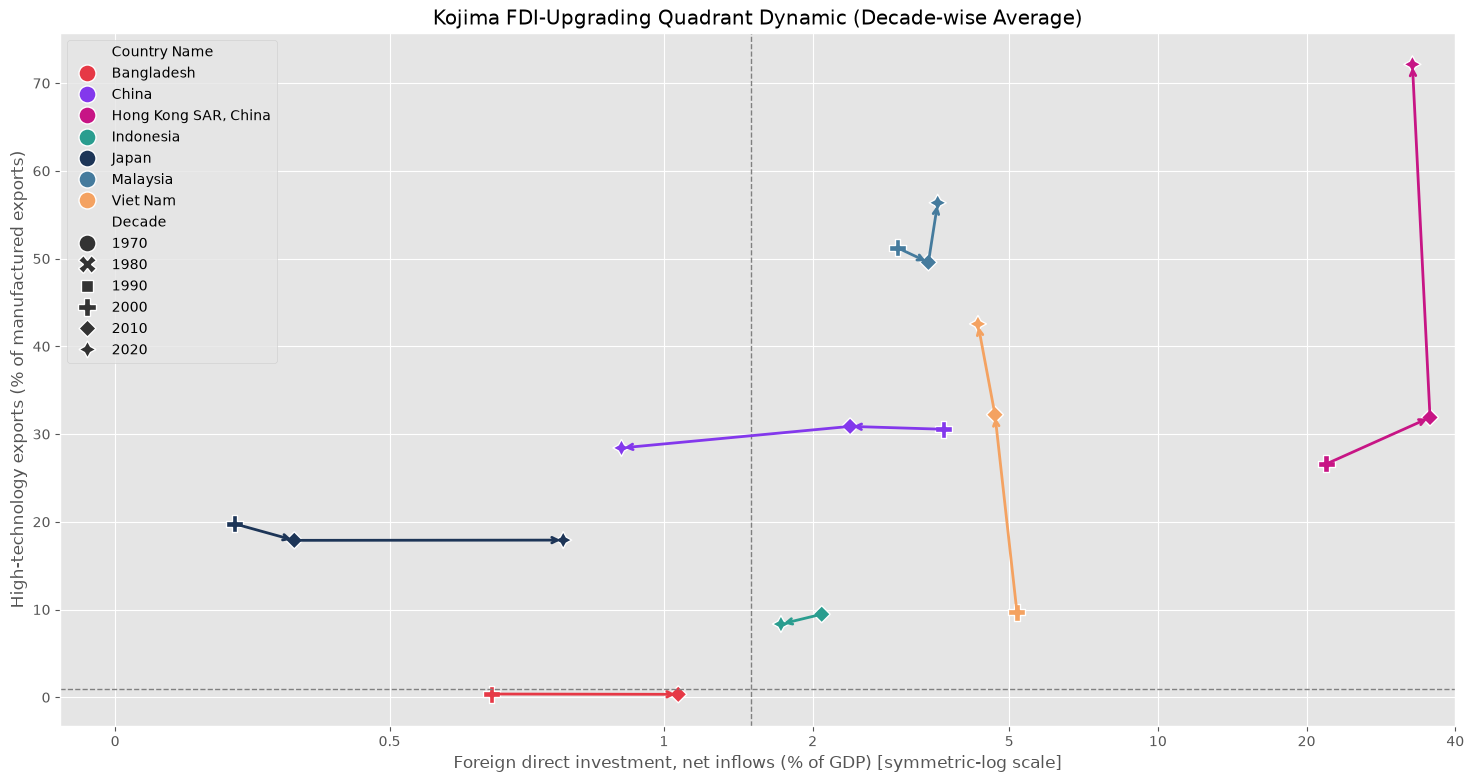

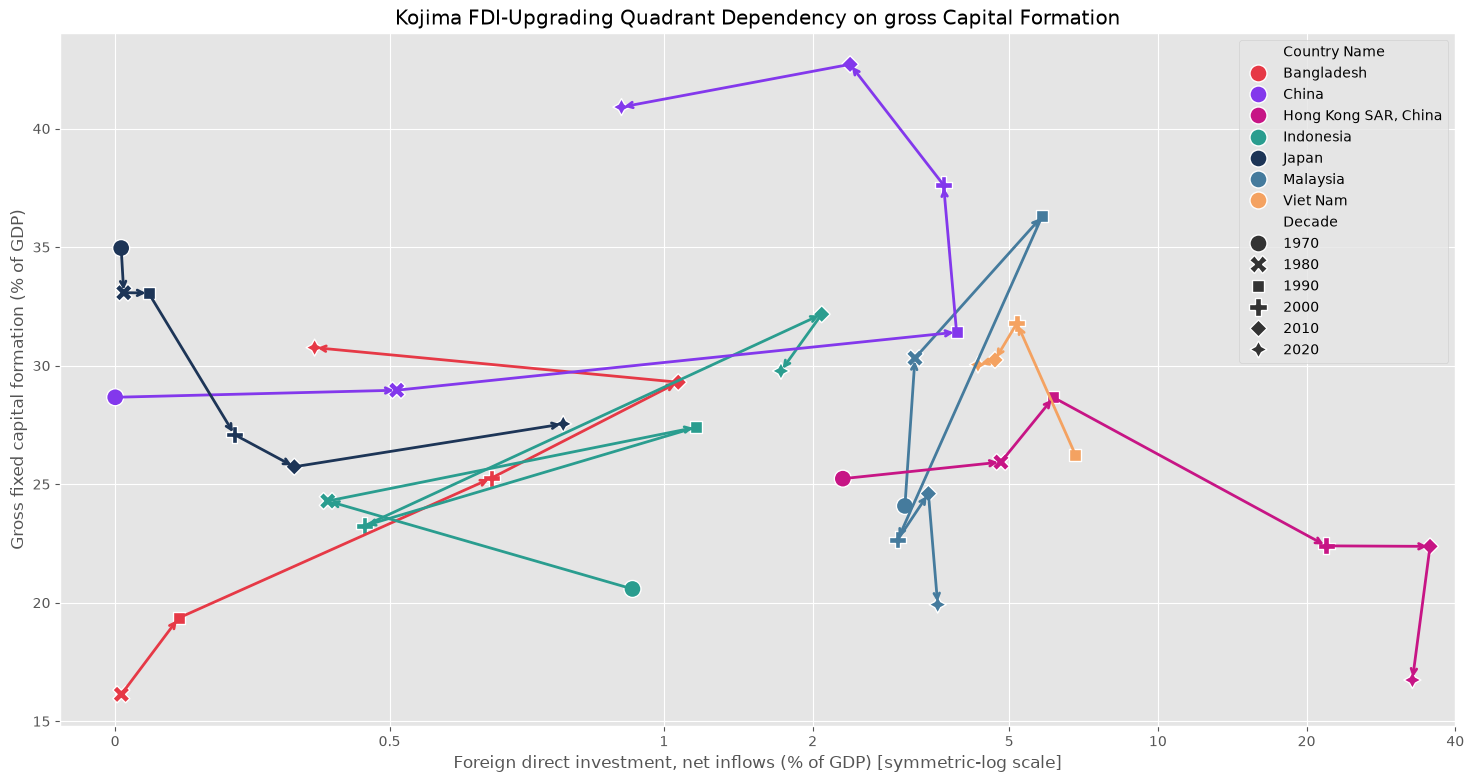

In [15]:
def fdi_symlog_axis():
    """Symmetric-log FDI axis (linear within +/-1% of GDP, logarithmic beyond): Hong Kong's FDI inflows dwarf the other economies."""
    plt.xscale('symlog', linthresh=1)
    plt.xlim(left=-0.1)
    plt.xticks([0, 0.5, 1, 2, 5, 10, 20, 40], ['0', '0.5', '1', '2', '5', '10', '20', '40'])
    plt.xlabel('Foreign direct investment, net inflows (% of GDP) [symmetric-log scale]')

countries = ['Bangladesh', 'Indonesia', 'Viet Nam', 'Malaysia', 'China', 'Japan', 'Hong Kong SAR, China']
cols = ['Foreign direct investment, net inflows (% of GDP)', 'High-technology exports (% of manufactured exports)', 'Gross fixed capital formation (% of GDP)']

decade_df = data[data['Country Name'].isin(countries)].copy()
decade_df['Decade'] = (decade_df['Time'] // 10) * 10
decade_df = decade_df.groupby(['Country Name', 'Decade'], as_index=False)[cols].mean().sort_values(['Country Name', 'Decade'])



plt.figure(figsize = (18, 9))
sns.scatterplot(data = decade_df, x = 'Foreign direct investment, net inflows (% of GDP)', y = 'High-technology exports (% of manufactured exports)', hue = 'Country Name', style = 'Decade', palette = palette, s = 150)
for c in countries:
    sub = decade_df[decade_df['Country Name'] == c].dropna(subset=['Foreign direct investment, net inflows (% of GDP)', 'High-technology exports (% of manufactured exports)']).reset_index(drop=True)
    for i in range(len(sub) - 1):
        plt.annotate('', xy=(sub.loc[i+1, 'Foreign direct investment, net inflows (% of GDP)'], sub.loc[i+1, 'High-technology exports (% of manufactured exports)']), xytext=(sub.loc[i, 'Foreign direct investment, net inflows (% of GDP)'], sub.loc[i, 'High-technology exports (% of manufactured exports)']), arrowprops=dict(arrowstyle='->', color=palette[c], lw=2))
fdi_symlog_axis()
plt.axvline(1.5, color='grey', linestyle='--', linewidth=1)
plt.axhline(1, color='grey', linestyle='--', linewidth=1)
plt.title('Kojima FDI-Upgrading Quadrant Dynamic (Decade-wise Average)')
save_fig('fig_kojima_hightech.png')
plt.show()

plt.figure(figsize = (18, 9))
sns.scatterplot(data = decade_df, x = 'Foreign direct investment, net inflows (% of GDP)', y = 'Gross fixed capital formation (% of GDP)', hue = 'Country Name', style = 'Decade', palette = palette, s = 150)
for c in countries:
    sub = decade_df[decade_df['Country Name'] == c].dropna(subset=['Foreign direct investment, net inflows (% of GDP)', 'Gross fixed capital formation (% of GDP)']).reset_index(drop=True)
    for i in range(len(sub) - 1):
        plt.annotate('', xy=(sub.loc[i+1, 'Foreign direct investment, net inflows (% of GDP)'], sub.loc[i+1, 'Gross fixed capital formation (% of GDP)']), xytext=(sub.loc[i, 'Foreign direct investment, net inflows (% of GDP)'], sub.loc[i, 'Gross fixed capital formation (% of GDP)']), arrowprops=dict(arrowstyle='->', color=palette[c], lw=2))
fdi_symlog_axis()
plt.title('Kojima FDI-Upgrading Quadrant Dependency on gross Capital Formation')
save_fig('fig_kojima_gcf.png')
plt.show()

### Kojima FDI-Upgrading Quadrant with *Medium and high-tech exports* (**added**)

Same design as the high-technology version above, with *Medium and high-tech exports (% manufactured exports)* (WDI `TX.MNF.TECH.ZS.UN`) on the vertical axis. This series is available for 1990-2024 in every economy, so each decade mean rests on up to ten observations instead of a handful.

**Differences from the high-tech figure (read before comparing the two).**
- Decade means use only the years in which **both** FDI and the export share are observed, so the two axes describe the same years. The 2020s therefore cover 2020-2024. The decade table printed under the figure shows the number of years behind each point.
- The horizontal dashed line is at **50%** (a majority of manufactured exports are medium/high-tech) and the vertical one at 1.5% of GDP. Both are illustrative cut-offs, not estimated thresholds; change `MHT_CUTOFF` / `FDI_CUTOFF` to test other values.
- The FDI axis is symmetric-log (see above). The medium/high-tech category is broader than high-tech and includes, for example, motor vehicles, machinery and chemicals, so a high value does not mean a high-technology export base.
- Same economies as the figure above, including Hong Kong.

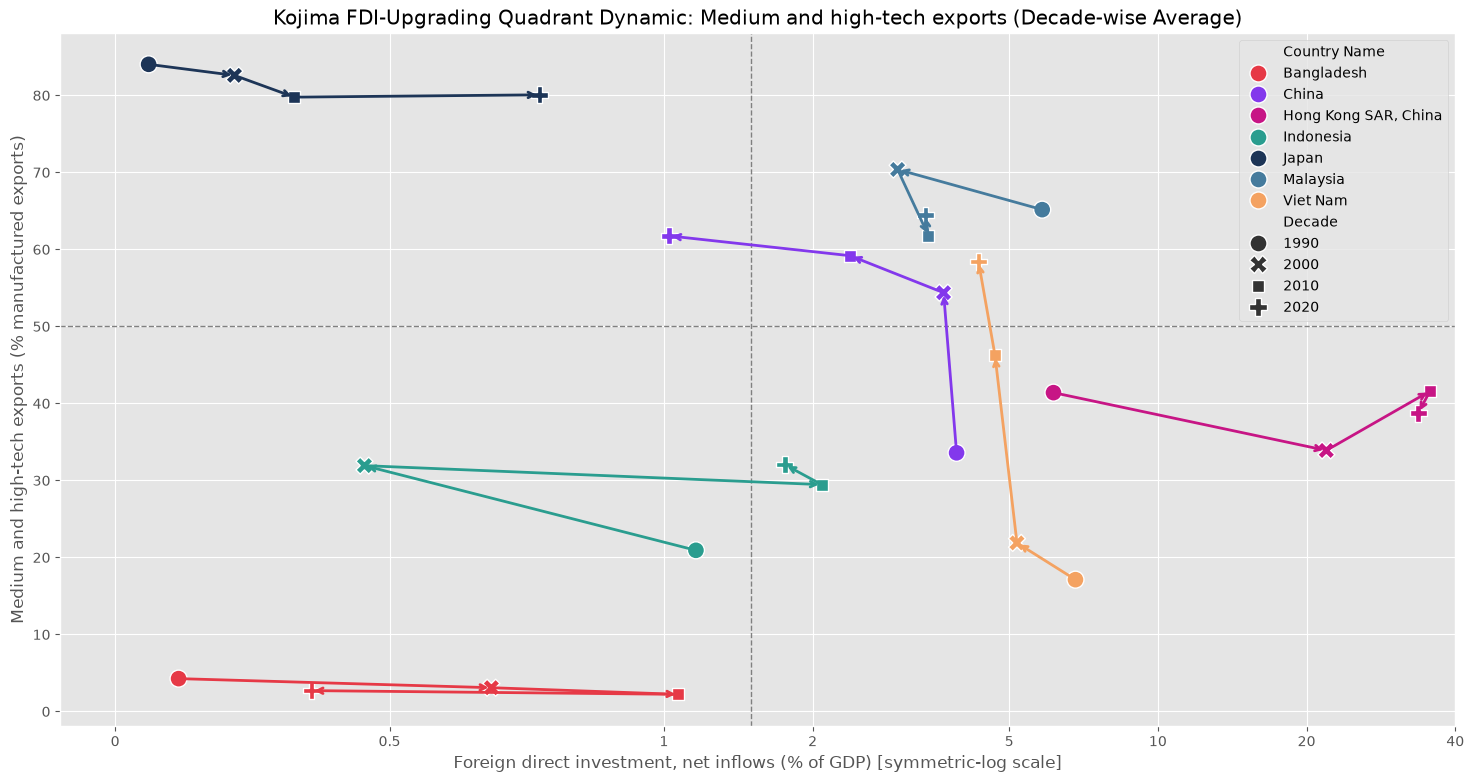

,Country Name,Decade,"Foreign direct investment, net inflows (% of GDP)",Medium and high-tech exports (% manufactured exports),Years
0,Bangladesh,1990,0.12,4.27,10
1,Bangladesh,2000,0.69,3.08,10
2,Bangladesh,2010,1.07,2.23,10
3,Bangladesh,2020,0.36,2.71,5
4,China,1990,3.91,33.59,10
5,China,2000,3.68,54.38,10
6,China,2010,2.38,59.18,10
7,China,2020,1.03,61.75,5
8,"Hong Kong SAR, China",1990,6.15,41.40,10
9,"Hong Kong SAR, China",2000,21.93,33.89,10


In [16]:
# Kojima FDI-upgrading quadrant: FDI vs. Medium and high-tech exports (decade averages)
mht = 'Medium and high-tech exports (% manufactured exports)'
fdi_col = 'Foreign direct investment, net inflows (% of GDP)'
FDI_CUTOFF = 1.5   # illustrative, as in the high-tech figure
MHT_CUTOFF = 50    # illustrative: a majority of manufactured exports are medium/high-tech

paired = data[data['Country Name'].isin(countries)].dropna(subset=[fdi_col, mht]).copy()
paired['Decade'] = (paired['Time'] // 10) * 10
decade_mht = (paired.groupby(['Country Name', 'Decade'], as_index=False)
              .agg(**{fdi_col: (fdi_col, 'mean'), mht: (mht, 'mean'), 'Years': ('Time', 'count')})
              .sort_values(['Country Name', 'Decade']).reset_index(drop=True))

plt.figure(figsize = (18, 9))
sns.scatterplot(data = decade_mht, x = fdi_col, y = mht, hue = 'Country Name', style = 'Decade', palette = palette, s = 150)
for c in countries:
    sub = decade_mht[decade_mht['Country Name'] == c].reset_index(drop=True)
    for i in range(len(sub) - 1):
        plt.annotate('', xy=(sub.loc[i+1, fdi_col], sub.loc[i+1, mht]), xytext=(sub.loc[i, fdi_col], sub.loc[i, mht]), arrowprops=dict(arrowstyle='->', color=palette[c], lw=2))
fdi_symlog_axis()
plt.axvline(FDI_CUTOFF, color='grey', linestyle='--', linewidth=1)
plt.axhline(MHT_CUTOFF, color='grey', linestyle='--', linewidth=1)
plt.title('Kojima FDI-Upgrading Quadrant Dynamic: Medium and high-tech exports (Decade-wise Average)')
save_fig('fig_kojima_medhightech.png')
plt.show()

decade_mht.round(2)

### Gendered Labor Absorption & Demographic Dividend Profile
Early-stage Flying Geese industrialization relies heavily on elastic labor supply and female labor absorption into light manufacturing (apparel/textiles).

Ozawa, T. (2005). Institutions, Industrial Upgrading, and Economic Performance in Japan: The 'Flying-Geese' Paradigm of Catch-up Growth. Edward Elgar Publishing (Specifically Chapter 2: Labor-Driven Stage – and Logic – of Reconstruction). Link to Book Source

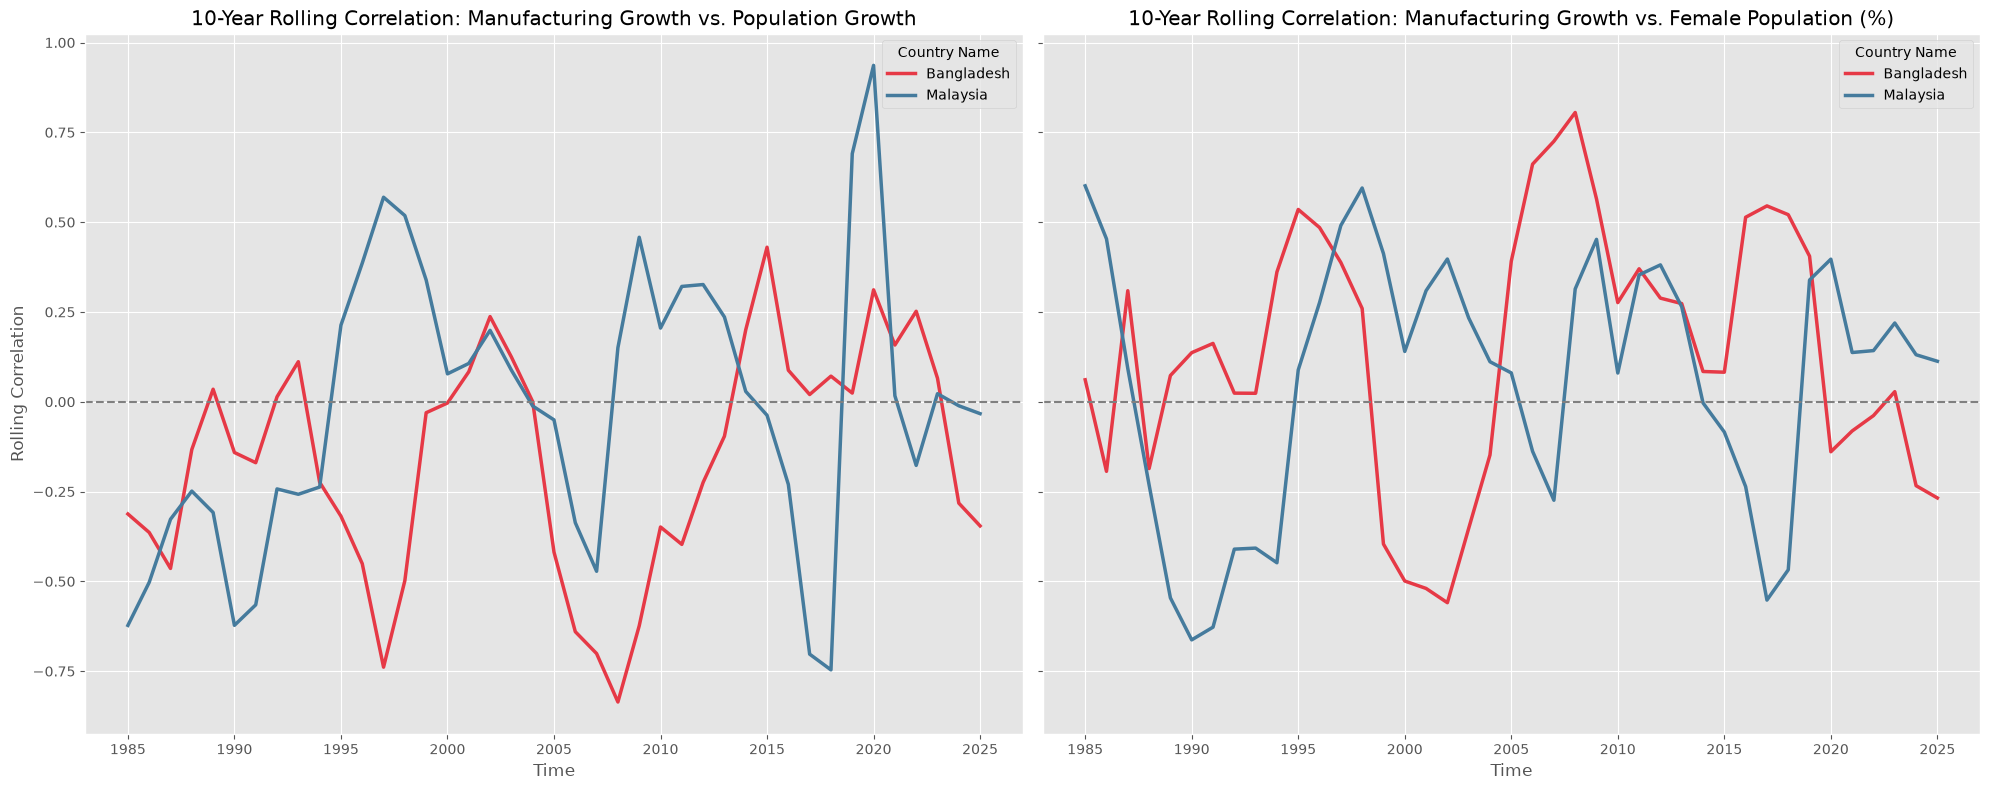

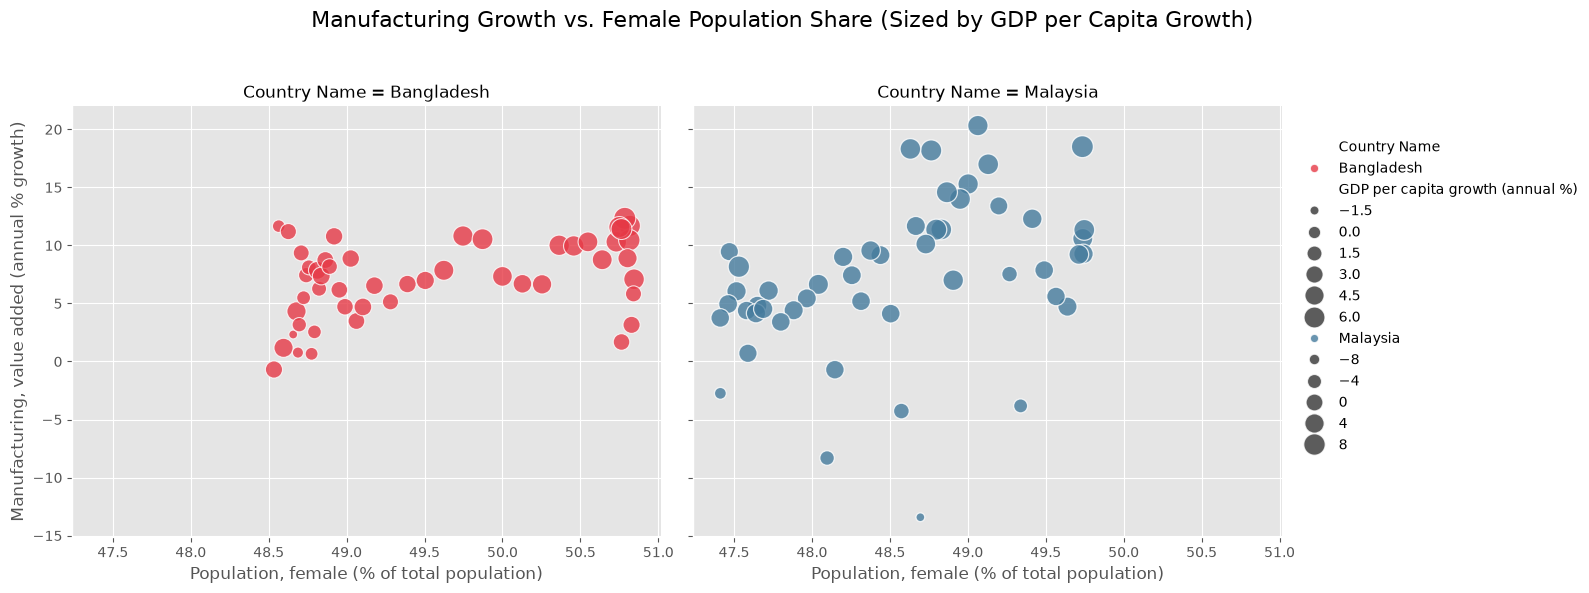

In [17]:
target_countries = ['Bangladesh', 'Malaysia']
vars_list = [
    'Population, female (% of total population)',
    'Population growth (annual %)',
    'Manufacturing, value added (annual % growth)',
    'GDP per capita growth (annual %)'
]

sub_df = data[data['Country Name'].isin(target_countries)].sort_values(['Country Name', 'Time']).dropna(subset=vars_list).copy()

def rolling_corr(frame, a, b, window=10):
    """Rolling correlation computed country by country (avoids groupby.apply, which changes behaviour across pandas versions)."""
    out = pd.Series(index=frame.index, dtype=float)
    for _, g in frame.groupby('Country Name'):
        out.loc[g.index] = g[a].rolling(window).corr(g[b])
    return out

mfg_growth = 'Manufacturing, value added (annual % growth)'
sub_df['Roll_Corr_PopGrowth'] = rolling_corr(sub_df, mfg_growth, 'Population growth (annual %)')
sub_df['Roll_Corr_FemalePop'] = rolling_corr(sub_df, mfg_growth, 'Population, female (% of total population)')

fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

sns.lineplot(data=sub_df, x='Time', y='Roll_Corr_PopGrowth', hue='Country Name', palette=palette, linewidth=2.5, ax=axes[0])
axes[0].axhline(0, color='gray', linestyle='--')
axes[0].set_title('10-Year Rolling Correlation: Manufacturing Growth vs. Population Growth')
axes[0].set_ylabel('Rolling Correlation')

sns.lineplot(data=sub_df, x='Time', y='Roll_Corr_FemalePop', hue='Country Name', palette=palette, linewidth=2.5, ax=axes[1])
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set_title('10-Year Rolling Correlation: Manufacturing Growth vs. Female Population (%)')
axes[1].set_ylabel('')

plt.tight_layout()
save_fig('fig_rolling_correlation.png')
plt.show()

g = sns.FacetGrid(sub_df, col='Country Name', height=6, aspect=1.1)
g.map_dataframe(sns.scatterplot, x='Population, female (% of total population)', y='Manufacturing, value added (annual % growth)', hue='Country Name', palette=palette, size='GDP per capita growth (annual %)', sizes=(40, 250), alpha=0.8)
g.add_legend()
g.fig.subplots_adjust(top=0.82)
g.fig.suptitle('Manufacturing Growth vs. Female Population Share (Sized by GDP per Capita Growth)', fontsize=16)
save_fig('fig_female_scatter.png', g.fig)
plt.show()

### Spearman Correlation and Kendall's $\tau$

Dowling, M., & Cheang, C. T. (2000). "Shifting comparative advantage in Asia: new tests of the 'flying geese' model." Journal of Asian Economics, 11(4), 443-463. DOI: 10.1016/S1049-0078(00)00070-1

**Caveat:** rank correlations of *levels* of trending series (Bangladesh's manufacturing share rises while China's falls) can be large and significant without any real co-movement, and the p-values ignore serial correlation. The first-difference check below (**Robustness**) shows whether the sign and size survive once common trends are removed.

**Added:** Hong Kong SAR is included as a further lead economy, and *Medium and high-tech exports (% manufactured exports)* as a third variable. Hong Kong's manufacturing share is only observed from 2000, so its manufacturing rows rest on a short overlap with Bangladesh (see the `n` column of the robustness table).

In [18]:
lead_countries = ['China', 'Korea, Rep.', 'Viet Nam', 'Hong Kong SAR, China']
variables = ['Manufacturing, value added (% of GDP)', 'High-technology exports (% of manufactured exports)',
             'Medium and high-tech exports (% manufactured exports)']
lags = [0, 5, 10]

results = []

for var in variables:
    pivoted = data.pivot(index='Time', columns='Country Name', values=var).sort_index()
    bd_series = pivoted['Bangladesh']
    
    for lead in lead_countries:
        if lead not in pivoted.columns:
            continue
        for k in lags:
            lead_lagged = pivoted[lead].shift(k)
            valid = pd.concat([bd_series, lead_lagged], axis=1).dropna()
            
            if len(valid) > 2:
                rho, sp_pval = spearmanr(valid.iloc[:, 0], valid.iloc[:, 1])
                tau, kt_pval = kendalltau(valid.iloc[:, 0], valid.iloc[:, 1])
                
                results.append({
                    'Variable': var,
                    'Lead Goose': lead,
                    'Lag (k)': k,
                    'Spearman Rho': rho,
                    'Spearman p-val': sp_pval,
                    'Kendall Tau': tau,
                    'Kendall p-val': kt_pval
                })

results_df = pd.DataFrame(results)
results_df

,Variable,Lead Goose,Lag (k),Spearman Rho,Spearman p-val,Kendall Tau,Kendall p-val
0,"Manufacturing, value added (% of GDP)",China,0,-0.937888,1.191823e-10,-0.818182,5.687024e-10
1,"Manufacturing, value added (% of GDP)",China,5,-0.958333,1.446991e-09,-0.852941,2.394031e-08
2,"Manufacturing, value added (% of GDP)",China,10,-0.804196,1.614769e-03,-0.636364,3.181647e-03
3,"Manufacturing, value added (% of GDP)","Korea, Rep.",0,0.571285,1.472156e-05,0.389388,6.606295e-05
4,"Manufacturing, value added (% of GDP)","Korea, Rep.",5,0.674045,3.863198e-07,0.470707,5.150530e-06
5,"Manufacturing, value added (% of GDP)","Korea, Rep.",10,0.686116,1.025129e-06,0.510256,3.533114e-06
6,"Manufacturing, value added (% of GDP)",Viet Nam,0,0.871429,2.708908e-07,0.685714,2.402167e-06
7,"Manufacturing, value added (% of GDP)",Viet Nam,5,0.829412,7.088454e-05,0.633333,3.362968e-04
8,"Manufacturing, value added (% of GDP)",Viet Nam,10,0.609091,4.669571e-02,0.527273,2.638448e-02
9,"Manufacturing, value added (% of GDP)","Hong Kong SAR, China",0,-0.963846,1.048440e-14,-0.853333,6.466550e-13


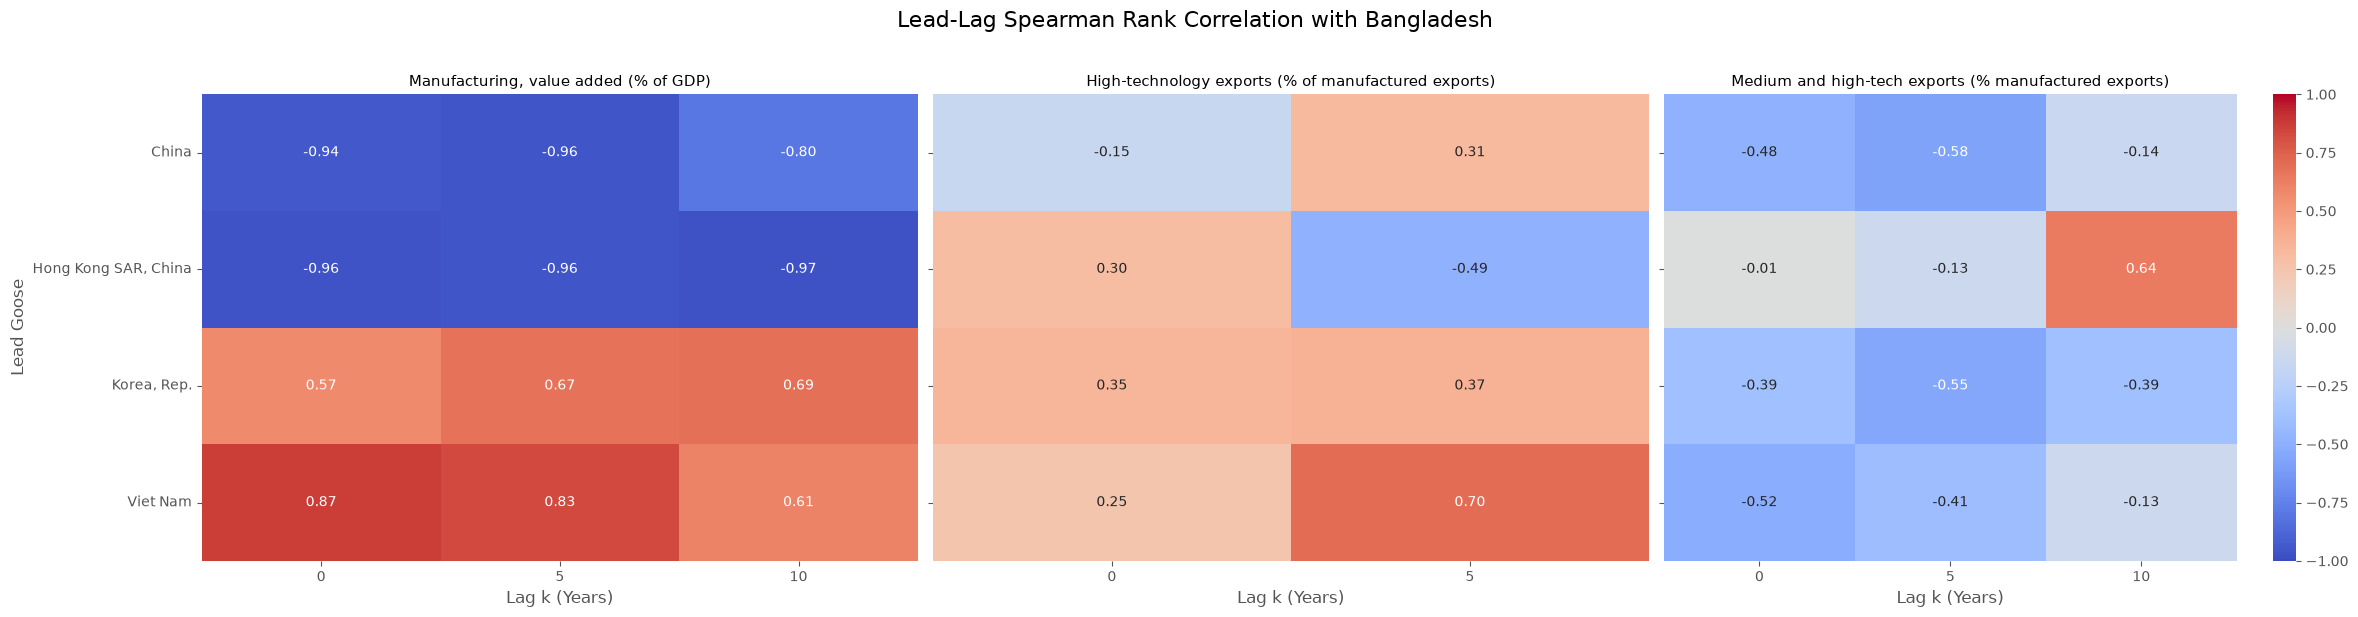

In [19]:
fig, axes = plt.subplots(1, len(variables), figsize=(8 * len(variables), 6), sharey=True)

for i, var in enumerate(variables):
    sub_res = results_df[results_df['Variable'] == var].pivot(index='Lead Goose', columns='Lag (k)', values='Spearman Rho')
    sns.heatmap(sub_res, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0, ax=axes[i], cbar=(i == len(variables) - 1))
    axes[i].set_title(var, fontsize=11)
    axes[i].set_xlabel('Lag k (Years)')
    if i > 0:
        axes[i].set_ylabel('')

plt.suptitle('Lead-Lag Spearman Rank Correlation with Bangladesh', fontsize=16, y=1.02)
plt.tight_layout()
save_fig('fig_spearman_heatmap.png')
plt.show()

**Robustness:** the same lead-lag rank correlations on year-on-year changes (first differences).

In [20]:
def lead_lag_table(transform=None):
    rows = []
    for var in variables:
        pivoted = data.pivot(index='Time', columns='Country Name', values=var).sort_index()
        if transform is not None:
            pivoted = transform(pivoted)
        for lead in lead_countries:
            if lead not in pivoted.columns:
                continue
            for k in lags:
                valid = pd.concat([pivoted['Bangladesh'], pivoted[lead].shift(k)], axis=1).dropna()
                if len(valid) > 2:
                    rho, p_s = spearmanr(valid.iloc[:, 0], valid.iloc[:, 1])
                    rows.append({'Variable': var, 'Lead Goose': lead, 'Lag (k)': k, 'n': len(valid), 'Spearman Rho': rho, 'Spearman p-val': p_s})
    return pd.DataFrame(rows)

levels_tbl = lead_lag_table()
diff_tbl = lead_lag_table(lambda p: p.diff())
(levels_tbl.merge(diff_tbl, on=['Variable', 'Lead Goose', 'Lag (k)'], suffixes=(' (levels)', ' (diff)'))
    [['Variable', 'Lead Goose', 'Lag (k)', 'Spearman Rho (levels)', 'Spearman p-val (levels)', 'Spearman Rho (diff)', 'Spearman p-val (diff)', 'n (diff)']]
    .round(3))

,Variable,Lead Goose,Lag (k),Spearman Rho (levels),Spearman p-val (levels),Spearman Rho (diff),Spearman p-val (diff),n (diff)
0,"Manufacturing, value added (% of GDP)",China,0,-0.938,0.000,-0.053,0.819,21
1,"Manufacturing, value added (% of GDP)",China,5,-0.958,0.000,0.147,0.587,16
2,"Manufacturing, value added (% of GDP)",China,10,-0.804,0.002,0.091,0.790,11
3,"Manufacturing, value added (% of GDP)","Korea, Rep.",0,0.571,0.000,0.016,0.914,49
4,"Manufacturing, value added (% of GDP)","Korea, Rep.",5,0.674,0.000,0.064,0.680,44
5,"Manufacturing, value added (% of GDP)","Korea, Rep.",10,0.686,0.000,0.032,0.846,39
6,"Manufacturing, value added (% of GDP)",Viet Nam,0,0.871,0.000,0.062,0.796,20
7,"Manufacturing, value added (% of GDP)",Viet Nam,5,0.829,0.000,0.054,0.850,15
8,"Manufacturing, value added (% of GDP)",Viet Nam,10,0.609,0.047,0.430,0.214,10
9,"Manufacturing, value added (% of GDP)","Hong Kong SAR, China",0,-0.964,0.000,0.127,0.554,24


### Pesaran (2004) Cross-Sectional Dependence (CD) Test

Panel diagnostic: ten economies that trade and compete with one another may share common shocks, which makes cross-sectional dependence a concern for panel unit-root and causality tests. A rejection motivates using CIPS (below) alongside IPS.

In [21]:
def pesaran_cd_test(df, var):
    pivoted = df.pivot(index='Time', columns='Country Name', values=var).dropna(axis=1, how='all')
    N = pivoted.shape[1]
    corr_matrix = pivoted.corr()
    
    cd_sum = 0
    for i in range(N - 1):
        for j in range(i + 1, N):
            s_i = pivoted.iloc[:, i]
            s_j = pivoted.iloc[:, j]
            valid = pd.concat([s_i, s_j], axis=1).dropna()
            T_ij = len(valid)
            if T_ij > 2:
                rho_ij = corr_matrix.iloc[i, j]
                if not np.isnan(rho_ij):
                    cd_sum += np.sqrt(T_ij) * rho_ij
                    
    cd_stat = np.sqrt(2 / (N * (N - 1))) * cd_sum
    p_val = 2 * (1 - norm.cdf(np.abs(cd_stat)))
    return cd_stat, p_val

continuous_vars = [col for col in data.select_dtypes(include=[np.number]).columns if col != 'Time']

cd_results = []
for var in continuous_vars:
    cd_stat, p_val = pesaran_cd_test(data, var)
    cd_results.append({
        'Variable': var,
        'Pesaran CD Stat': cd_stat,
        'p-value': p_val
    })

cd_df = pd.DataFrame(cd_results)
cd_df

,Variable,Pesaran CD Stat,p-value
0,"Agriculture, forestry, and fishing, value adde...",34.615388,0.000000e+00
1,Exports of goods and services (% of GDP),20.073376,0.000000e+00
2,"Foreign direct investment, net inflows (% of GDP)",11.070497,0.000000e+00
3,GDP (constant 2015 US$),44.267306,0.000000e+00
4,GDP growth (annual %),13.360653,0.000000e+00
5,GDP per capita (constant 2015 US$),43.858155,0.000000e+00
6,GDP per capita growth (annual %),10.931378,0.000000e+00
7,Gross fixed capital formation (% of GDP),-0.792482,4.280796e-01
8,Gross fixed capital formation (annual % growth),10.056613,0.000000e+00
9,Gross fixed capital formation (constant 2015 US$),27.209161,0.000000e+00


### Zivot-Andrews (1992) Endogenous Structural Break Unit Root Test


Zivot, E., & Andrews, D. W. K. (1992). "Further Evidence on the Great Crash, the Oil-Price Shock, and the Unit-Root Hypothesis." Journal of Business & Economic Statistics, 10(3), 251–270. DOI: 10.2307/1391541

**Reading the output.** Zivot-Andrews tests the null of a unit root *without* a break against stationarity *with* one break. The estimated break date is only meaningful when that null is rejected; where it is not (`Reject unit root (5%) = False`), the date is just the point that makes the statistic most negative and should not be read as a confirmed structural break. The figure below draws such dates dotted and labels them *n.s.*

In [22]:

bd_df = (
    data[data['Country Name'] == 'Bangladesh']
    .sort_values('Time')
)

za_vars = [
    'Manufacturing, value added (% of GDP)',
    'Exports of goods and services (% of GDP)',
    'Gross fixed capital formation (% of GDP)'
]

za_results = []

for var in za_vars:
    sub = (
        bd_df[['Time', var]]
        .dropna()
        .reset_index(drop=True)
    )

    for reg_type in ['c', 't', 'ct']:
        za_stat, p_val, cv_dict, baselag, bidx = (
            zivot_andrews(
                sub[var].to_numpy(),
                regression=reg_type,
                autolag='AIC'
            )
        )

        break_year = int(sub.loc[bidx, 'Time'])

        za_results.append({
            'Variable': var,
            'Regression': reg_type,
            'ZA Stat': za_stat,
            'p-value': p_val,
            'Break Year': break_year,
            'Reject unit root (5%)': bool(za_stat < cv_dict['5%']),
            'CV (5%)': cv_dict['5%'],
            'Selected Lags': baselag
        })

za_df = pd.DataFrame(za_results)
za_df

,Variable,Regression,ZA Stat,p-value,Break Year,Reject unit root (5%),CV (5%),Selected Lags
0,"Manufacturing, value added (% of GDP)",c,-4.998388,0.028930,2015,True,-4.81067,0
1,"Manufacturing, value added (% of GDP)",t,-4.079789,0.114373,2011,False,-4.40580,0
2,"Manufacturing, value added (% of GDP)",ct,-4.656587,0.151281,2015,False,-5.07332,0
3,Exports of goods and services (% of GDP),c,-3.756649,0.508936,2015,False,-4.81067,0
4,Exports of goods and services (% of GDP),t,-3.428365,0.393253,2012,False,-4.40580,0
5,Exports of goods and services (% of GDP),ct,-3.944261,0.541572,2004,False,-5.07332,0
6,Gross fixed capital formation (% of GDP),c,-1.485093,0.999000,1995,False,-4.81067,0
7,Gross fixed capital formation (% of GDP),t,-1.648839,0.999000,2019,False,-4.40580,0
8,Gross fixed capital formation (% of GDP),ct,-1.781400,0.999000,2017,False,-5.07332,0


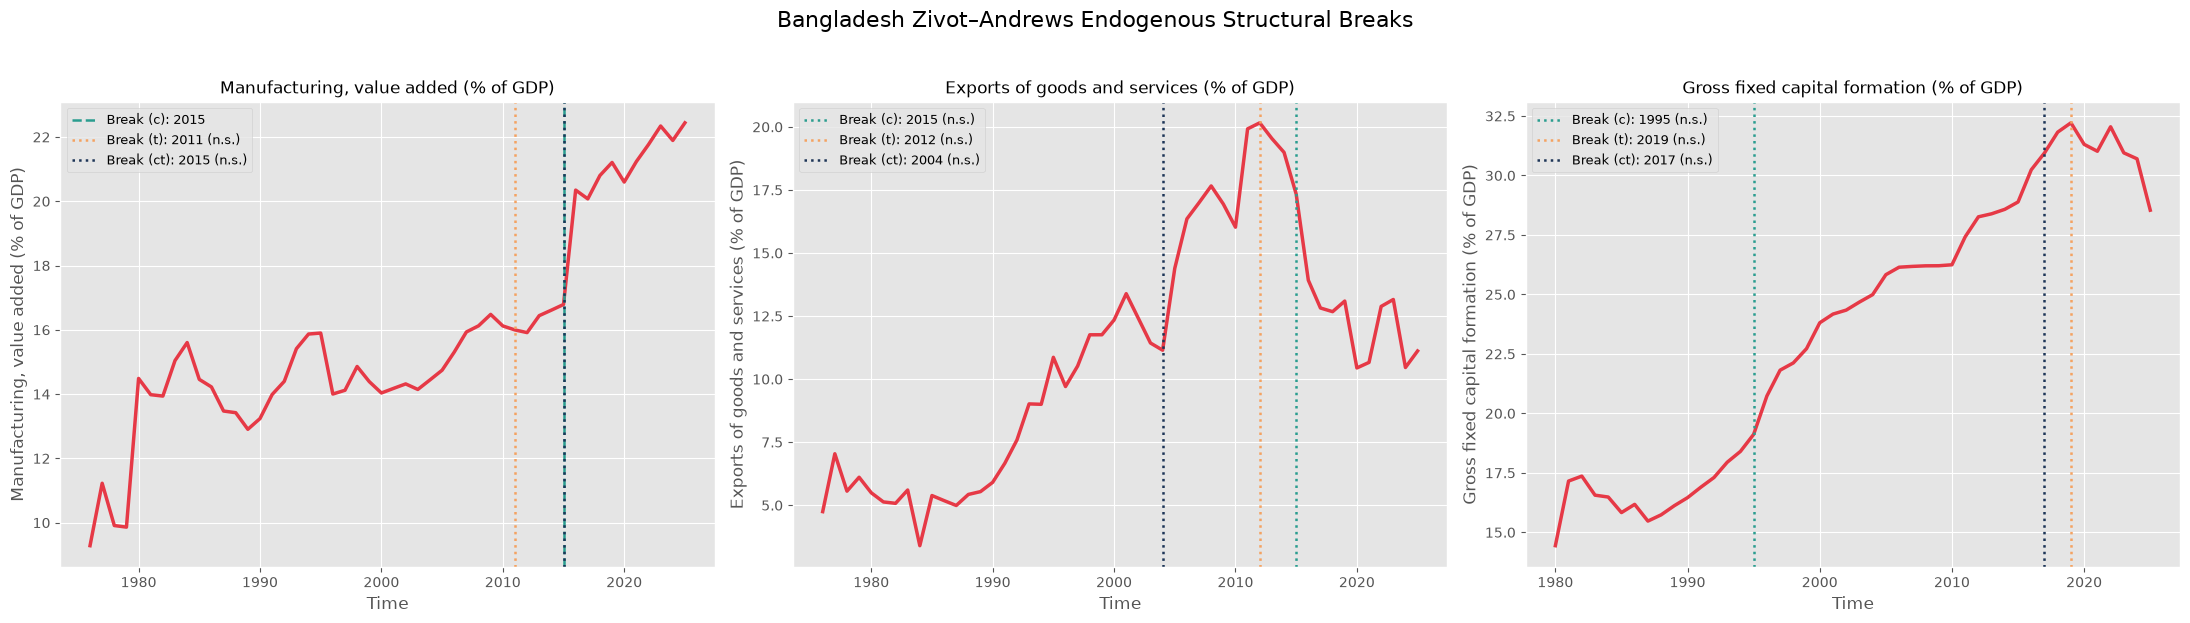

In [23]:

fig, axes = plt.subplots(1, len(za_vars), figsize=(22, 6))

break_colors = {
    'c': '#2A9D8F',
    't': '#F4A261',
    'ct': '#1D3557'
}

for i, var in enumerate(za_vars):
    ax = axes[i]

    # Select and chronologically sort observations
    sub = (
        bd_df[['Time', var]]
        .dropna()
        .sort_values('Time')
    )

    # Plot the observed time series
    sns.lineplot(
        data=sub,
        x='Time',
        y=var,
        color='#E63946',
        linewidth=2.5,
        ax=ax
    )

    # Retrieve results for this indicator
    var_breaks = za_df[za_df['Variable'] == var]

    for _, row in var_breaks.iterrows():
        # Use 'Regression' in the corrected results table
        b_type = row['Regression']
        b_year = row['Break Year']

        ax.axvline(
            x=b_year,
            color=break_colors[b_type],
            linestyle='--' if row['Reject unit root (5%)'] else ':',
            linewidth=1.8,
            label=f"Break ({b_type}): {b_year}" + ('' if row['Reject unit root (5%)'] else ' (n.s.)')
        )

    ax.set_title(var, fontsize=12)
    ax.set_xlabel('Time')
    ax.set_ylabel(var)
    ax.legend(fontsize=9, loc='best')

plt.suptitle(
    'Bangladesh Zivot–Andrews Endogenous Structural Breaks',
    fontsize=16,
    y=1.03
)

plt.tight_layout()
save_fig('fig_zivot_andrews.png')
plt.show()

### Im-Pesaran-Shin (2003) & Pesaran CIPS (2007) Panel Unit Root Tests

Im, K. S., Pesaran, M. H., & Shin, Y. (2003). "Testing for unit roots in heterogeneous panels." Journal of Econometrics, 115(1), 53-74. DOI: 10.1016/S0304-4076(03)00092-7

Pesaran, M. H. (2007). "A simple panel unit root test in the presence of cross-section dependence." Journal of Applied Econometrics, 22(2), 265-312. DOI: 10.1002/jae.951

Maddala, G. S., & Wu, S. (1999). "A comparative study of unit root tests with panel data and a new simple test." Oxford Bulletin of Economics and Statistics, 61(S1), 631-652. DOI: 10.1111/1468-0084.0610s1631

**Implementation notes.** The IPS *W* statistic below standardises the mean ADF t-statistic with fixed moments (-1.504, 0.855) instead of the T- and lag-specific moments tabulated in IPS (2003), so treat it as approximate. For that reason a Fisher-type ADF test (Maddala-Wu) is reported next to it: it combines the country-level ADF p-values and needs no tabulated moments, but, like IPS, it assumes cross-sectional independence. CIPS allows for cross-sectional dependence; the -2.33 cut-off is an approximate reference, and exact critical values depend on N and T (Pesaran, 2007, Tables I-II).

In [24]:
def ips_cips_panel_tests(df, var):
    """Panel unit-root statistics for one variable.

    Returns (t-bar, IPS W [approx.], IPS p, Fisher-ADF p, CIPS).
    Country ADF regressions include an intercept and an AIC-selected lag length.
    """
    pivoted = df.pivot(index='Time', columns='Country Name', values=var).sort_index()
    cs_mean = pivoted.mean(axis=1)

    adf_stats, adf_pvals, cadf_stats = [], [], []
    for col in pivoted.columns:
        s = pivoted[col].dropna()
        T = len(s)
        if T < 12:
            continue
        max_lag = int(np.floor(12 * (T / 100) ** 0.25))
        try:
            adf_res = adfuller(s, regression='c', maxlag=max_lag, autolag='AIC')
        except (ValueError, np.linalg.LinAlgError):
            continue          # e.g. constant series
        adf_stats.append(adf_res[0])
        adf_pvals.append(adf_res[1])

        # CADF(1): dy_t on y_{t-1}, ybar_{t-1}, dybar_t
        reg_df = pd.DataFrame({
            'dy': s.diff(),
            'y_l1': s.shift(1),
            'cs_l1': cs_mean.shift(1).reindex(s.index),
            'd_cs': cs_mean.diff().reindex(s.index),
        }).dropna()
        if len(reg_df) > 6:
            X = sm.add_constant(reg_df[['y_l1', 'cs_l1', 'd_cs']])
            t_stat = sm.OLS(reg_df['dy'], X).fit().tvalues['y_l1']
            cadf_stats.append(np.clip(t_stat, -6.19, 2.61))   # truncation constants for the intercept-only case

    N = len(adf_stats)
    if N == 0:
        return np.nan, np.nan, np.nan, np.nan, np.nan
    t_bar = np.mean(adf_stats)
    w_stat = np.sqrt(N) * (t_bar - (-1.504)) / np.sqrt(0.855)
    ips_p = norm.cdf(w_stat)
    fisher_stat = -2 * np.sum(np.log(np.clip(adf_pvals, 1e-12, 1)))
    fisher_p = chi2.sf(fisher_stat, 2 * N)
    cips = np.mean(cadf_stats) if cadf_stats else np.nan
    return t_bar, w_stat, ips_p, fisher_p, cips

continuous_vars = [col for col in data.select_dtypes(include=[np.number]).columns if col != 'Time']

pur_results = []

for var in continuous_vars:
    t_bar_0, w_0, p_0, fisher_0, cips_0 = ips_cips_panel_tests(data, var)

    diff_df = data[['Country Name', 'Time', var]].sort_values(['Country Name', 'Time']).copy()
    diff_df[var] = diff_df.groupby('Country Name')[var].diff()
    t_bar_1, w_1, p_1, fisher_1, cips_1 = ips_cips_panel_tests(diff_df, var)

    order = 'I(0)' if (fisher_0 < 0.05 or cips_0 < -2.33) else ('I(1)' if (fisher_1 < 0.05 or cips_1 < -2.33) else '> I(1)')

    pur_results.append({
        'Variable': var,
        'IPS W-stat (Level)': w_0,
        'IPS p-val (Level)': p_0,
        'Fisher-ADF p (Level)': fisher_0,
        'CIPS (Level)': cips_0,
        'IPS W-stat (1st Diff)': w_1,
        'IPS p-val (1st Diff)': p_1,
        'Fisher-ADF p (1st Diff)': fisher_1,
        'CIPS (1st Diff)': cips_1,
        'Order': order
    })

pur_df = pd.DataFrame(pur_results)
pur_df

,Variable,IPS W-stat (Level),IPS p-val (Level),Fisher-ADF p (Level),CIPS (Level),IPS W-stat (1st Diff),IPS p-val (1st Diff),Fisher-ADF p (1st Diff),CIPS (1st Diff),Order
0,"Agriculture, forestry, and fishing, value adde...",-6.896539,2.664231e-12,6.540861e-14,-2.525252,-11.125133,4.733212e-29,1.989834e-38,-5.297488,I(0)
1,Exports of goods and services (% of GDP),-0.567738,2.851063e-01,3.223599e-01,-1.405375,-15.373167,1.238775e-53,2.580902e-53,-5.401751,I(1)
2,"Foreign direct investment, net inflows (% of GDP)",-0.796803,2.127826e-01,2.986698e-02,-3.160405,-14.847852,3.591707e-50,6.648737e-53,-5.863871,I(0)
3,GDP (constant 2015 US$),10.519647,1.000000e+00,9.648605e-01,-1.402346,-1.556727,5.976770e-02,4.753198e-13,-4.836069,I(1)
4,GDP growth (annual %),-10.341305,2.291259e-25,2.623845e-30,-4.540187,-17.325424,1.512289e-67,4.004189e-60,-6.190000,I(0)
5,GDP per capita (constant 2015 US$),8.384795,1.000000e+00,9.909888e-01,-0.796683,-4.755865,9.879942e-07,6.957794e-18,-3.735179,I(1)
6,GDP per capita growth (annual %),-9.667463,2.072636e-22,2.214359e-29,-4.361153,-14.053993,3.640524e-45,5.141092e-45,-6.190000,I(0)
7,Gross fixed capital formation (% of GDP),-1.007192,1.569213e-01,2.527156e-01,-1.752858,-9.761443,8.239698e-23,3.529961e-24,-5.043652,I(1)
8,Gross fixed capital formation (annual % growth),-10.762320,2.592403e-27,3.627884e-29,-4.644488,-14.315307,8.779344e-47,9.590978e-49,-6.096505,I(0)
9,Gross fixed capital formation (constant 2015 US$),4.835647,9.999993e-01,9.809785e-01,0.032732,-10.038266,5.173861e-24,2.539884e-29,-3.973590,I(1)


### Dumitrescu-Hurlin (2012) Panel Granger Non-Causality Test (plus Pairwise Toda-Yamamoto for BD)

Dumitrescu, E. I., & Hurlin, C. (2012). "Testing for Granger non-causality in heterogeneous panels." Economic Modelling, 29(4), 1450-1460. DOI: 10.1016/j.econmod.2012.02.014

Toda, H. Y., & Yamamoto, T. (1995). "Statistical inference in vector autoregressions with possibly integrated processes." Journal of Econometrics, 66(1-2), 225-250. DOI: 10.1016/0304-4076(94)01616-8

**Direction of causality tested:** whether FDI (% of GDP) and gross fixed capital formation (% of GDP) Granger-cause manufacturing value added (% of GDP), high-technology exports and medium and high-tech exports across the Asian geese, and specifically whether the link breaks down in Bangladesh. Chain examined: FDI <-> Manufacturing <-> Exports <-> GDP per capita growth.

**Caveats (read before citing a p-value).**
- Dumitrescu-Hurlin assumes stationary series. The headline column (`Panel DH p-val`) runs on levels, as in the paper; `Panel DH p-val (stationarised)` repeats the test on first differences whenever either variable is not I(0) in the panel unit-root table above (**Robustness**).
- The Toda-Yamamoto test for Bangladesh uses a fixed lag (k = 1, d_max = 1) and is estimated on only `BD TY n_obs` observations. Pairs involving high-technology exports have very few usable years for Bangladesh (see `BD TY n_obs`), so very small p-values there reflect a tiny sample as much as a strong relationship. Pairs involving medium and high-tech exports have a much longer sample (1990-2024), so their `n_obs` is larger, but the series is highly persistent.
- Eighteen directions are tested at once; `(Holm)` columns adjust for multiple testing (**Robustness**).

In [25]:
def _wald_chi2(model, X, test_cols):
    """Wald statistic for the joint exclusion of `test_cols` (F-statistic x number of restrictions)."""
    r_mat = np.zeros((len(test_cols), X.shape[1]))
    for idx, col_name in enumerate(test_cols):
        r_mat[idx, X.columns.get_loc(col_name)] = 1
    return float(model.wald_test(r_mat, use_f=True, scalar=True).statistic) * len(test_cols)


def dh_and_ty_causality(df, x_col, y_col, k=1, d_max=1, difference=False):
    """Does x Granger-cause y?  Returns the panel DH statistics and the Bangladesh Toda-Yamamoto test.

    difference=True first-differences x and y within each country (use when either is not I(0)).
    Returns (W-bar, Z-tilde, DH p, BD TY Wald, BD TY p, BD TY n_obs).
    """
    w_stats, t_list = [], []
    bd_ty_wald, bd_ty_pval, bd_n = np.nan, np.nan, 0

    for c in df['Country Name'].unique():
        sub = df[df['Country Name'] == c].sort_values('Time')[['Time', x_col, y_col]].dropna()
        if difference:
            sub[[x_col, y_col]] = sub[[x_col, y_col]].diff()
            sub = sub.dropna()
        sub = sub.reset_index(drop=True)

        if len(sub) > (2 * k + 5):
            reg_df = pd.DataFrame({'y': sub[y_col]})
            for lag in range(1, k + 1):
                reg_df[f'y_l{lag}'] = sub[y_col].shift(lag)
                reg_df[f'x_l{lag}'] = sub[x_col].shift(lag)
            reg_df = reg_df.dropna()

            T_i = len(reg_df)
            if T_i > (2 * k + 2):
                X = sm.add_constant(reg_df.drop(columns=['y']))
                model = sm.OLS(reg_df['y'], X).fit()
                w_stats.append(_wald_chi2(model, X, [f'x_l{lag}' for lag in range(1, k + 1)]))
                t_list.append(T_i)

        if c == 'Bangladesh' and len(sub) > (2 * (k + d_max) + 5):
            ty_df = pd.DataFrame({'y': sub[y_col]})
            for lag in range(1, k + d_max + 1):
                ty_df[f'y_l{lag}'] = sub[y_col].shift(lag)
                ty_df[f'x_l{lag}'] = sub[x_col].shift(lag)
            ty_df = ty_df.dropna()

            if len(ty_df) > (2 * (k + d_max) + 2):
                X_ty = sm.add_constant(ty_df.drop(columns=['y']))
                model_ty = sm.OLS(ty_df['y'], X_ty).fit()
                # Toda-Yamamoto: test only the first k lags; the d_max extra lags are left unrestricted
                bd_ty_wald = _wald_chi2(model_ty, X_ty, [f'x_l{lag}' for lag in range(1, k + 1)])
                bd_ty_pval = chi2.sf(bd_ty_wald, k)
                bd_n = len(ty_df)

    N = len(w_stats)
    if N > 0:
        w_bar = np.mean(w_stats)
        T_avg = np.mean(t_list)
        e_w = k * (T_avg - 2 * k - 1) / (T_avg - 2 * k - 3)
        v_w = 2 * k * ((T_avg - 2 * k - 1) ** 2) * (T_avg - k - 3) / (((T_avg - 2 * k - 3) ** 2) * (T_avg - 2 * k - 5))
        z_tilde = np.sqrt(N) * (w_bar - e_w) / np.sqrt(v_w)
        dh_pval = 2 * norm.sf(np.abs(z_tilde))
    else:
        w_bar, z_tilde, dh_pval = np.nan, np.nan, np.nan

    return w_bar, z_tilde, dh_pval, bd_ty_wald, bd_ty_pval, bd_n

fdi = 'Foreign direct investment, net inflows (% of GDP)'
gcf = 'Gross fixed capital formation (% of GDP)'
mfg = 'Manufacturing, value added (% of GDP)'
htx = 'High-technology exports (% of manufactured exports)'
mhtx = 'Medium and high-tech exports (% manufactured exports)'
exp = 'Exports of goods and services (% of GDP)'
gdppc = 'GDP per capita growth (annual %)'

causal_pairs = [
    (fdi, mfg), (mfg, fdi),
    (gcf, mfg), (mfg, gcf),
    (fdi, htx), (htx, fdi),
    (gcf, htx), (htx, gcf),
    (fdi, mhtx), (mhtx, fdi),
    (gcf, mhtx), (mhtx, gcf),
    (mfg, exp), (exp, mfg),
    (exp, gdppc), (gdppc, exp),
    (mfg, gdppc), (gdppc, mfg)
]

integration_order = pur_df.set_index('Variable')['Order']

causality_results = []
for x_var, y_var in causal_pairs:
    if x_var in data.columns and y_var in data.columns:
        w_bar, z_tilde, dh_p, bd_w, bd_p, bd_n = dh_and_ty_causality(data, x_var, y_var, k=1, d_max=1)
        needs_diff = integration_order.get(x_var, 'I(0)') != 'I(0)' or integration_order.get(y_var, 'I(0)') != 'I(0)'
        dh_p_stat = dh_and_ty_causality(data, x_var, y_var, k=1, d_max=1, difference=True)[2] if needs_diff else dh_p
        causality_results.append({
            'Direction': f"{x_var} -> {y_var}",
            'DH W-bar': w_bar,
            'DH Z-tilde': z_tilde,
            'Panel DH p-val': dh_p,
            'Panel DH p-val (stationarised)': dh_p_stat,
            'Differenced?': needs_diff,
            'BD Toda-Yamamoto Wald': bd_w,
            'BD TY p-val': bd_p,
            'BD TY n_obs': bd_n,
        })

causality_df = pd.DataFrame(causality_results)
for col in ['Panel DH p-val', 'BD TY p-val']:
    causality_df[f'{col} (Holm)'] = multipletests(causality_df[col].fillna(1.0), method='holm')[1]
causality_df

,Direction,DH W-bar,DH Z-tilde,Panel DH p-val,Panel DH p-val (stationarised),Differenced?,BD Toda-Yamamoto Wald,BD TY p-val,BD TY n_obs,Panel DH p-val (Holm),BD TY p-val (Holm)
0,"Foreign direct investment, net inflows (% of G...",2.276796,2.421571,1.545357e-02,0.015454,False,0.047801,8.269346e-01,48,2.008965e-01,1.000000
1,"Manufacturing, value added (% of GDP) -> Forei...",1.961661,1.791861,7.315522e-02,0.073155,False,1.307957,2.527648e-01,48,8.047074e-01,1.000000
2,Gross fixed capital formation (% of GDP) -> Ma...,1.870009,1.603628,1.087960e-01,0.582964,True,0.001482,9.692871e-01,44,1.000000e+00,1.000000
3,"Manufacturing, value added (% of GDP) -> Gross...",1.229398,0.325893,7.445055e-01,0.725564,True,0.187391,6.650969e-01,44,1.000000e+00,1.000000
4,"Foreign direct investment, net inflows (% of G...",2.081955,1.360437,1.736916e-01,0.173692,False,0.449373,5.026329e-01,8,1.000000e+00,1.000000
5,High-technology exports (% of manufactured exp...,2.143384,1.456338,1.452991e-01,0.145299,False,0.641478,4.231763e-01,8,1.000000e+00,1.000000
6,Gross fixed capital formation (% of GDP) -> Hi...,1.561461,0.547864,5.837850e-01,0.005154,True,0.852538,3.558354e-01,8,1.000000e+00,1.000000
7,High-technology exports (% of manufactured exp...,3.229225,3.151507,1.624302e-03,0.172349,True,23.938160,9.948021e-07,8,2.274022e-02,0.000018
8,"Foreign direct investment, net inflows (% of G...",1.772743,1.396618,1.625283e-01,0.162528,False,3.620940,5.705662e-02,33,1.000000e+00,0.912906
9,Medium and high-tech exports (% manufactured e...,1.252922,0.365054,7.150707e-01,0.715071,False,0.317556,5.730798e-01,33,1.000000e+00,1.000000


### Comparative Directed Granger-Causality Network Graph

For Panel A (Dumitrescu-Hurlin Panel Causality Test):Dumitrescu, E.-I., & Hurlin, C. (2012). Testing for Granger non-causality in heterogeneous panels. Economic Modelling, 29(4), 1450–1460. https://doi.org/10.1016/j.econmod.2012.02.014

For Panel B (Toda-Yamamoto Country-Specific Causality Test for Mixed $I(0)/I(1)$ Series):Toda, H. Y., & Yamamoto, T. (1995). Statistical inference in vector autoregressions with possibly integrated processes. Journal of Econometrics, 66(1–2), 225–250. https://doi.org/10.1016/0304-4076(94)01616-8

For the Theoretical FDI $\rightarrow$ Manufacturing Link Tested in the Graph:Kojima, K. (2000). The "flying geese" model of Asian economic development: Origin, theoretical extensions, and regional policy implications. Journal of Asian Economics, 11(4), 375–401. https://doi.org/10.1016/S1049-0078(00)00067-1

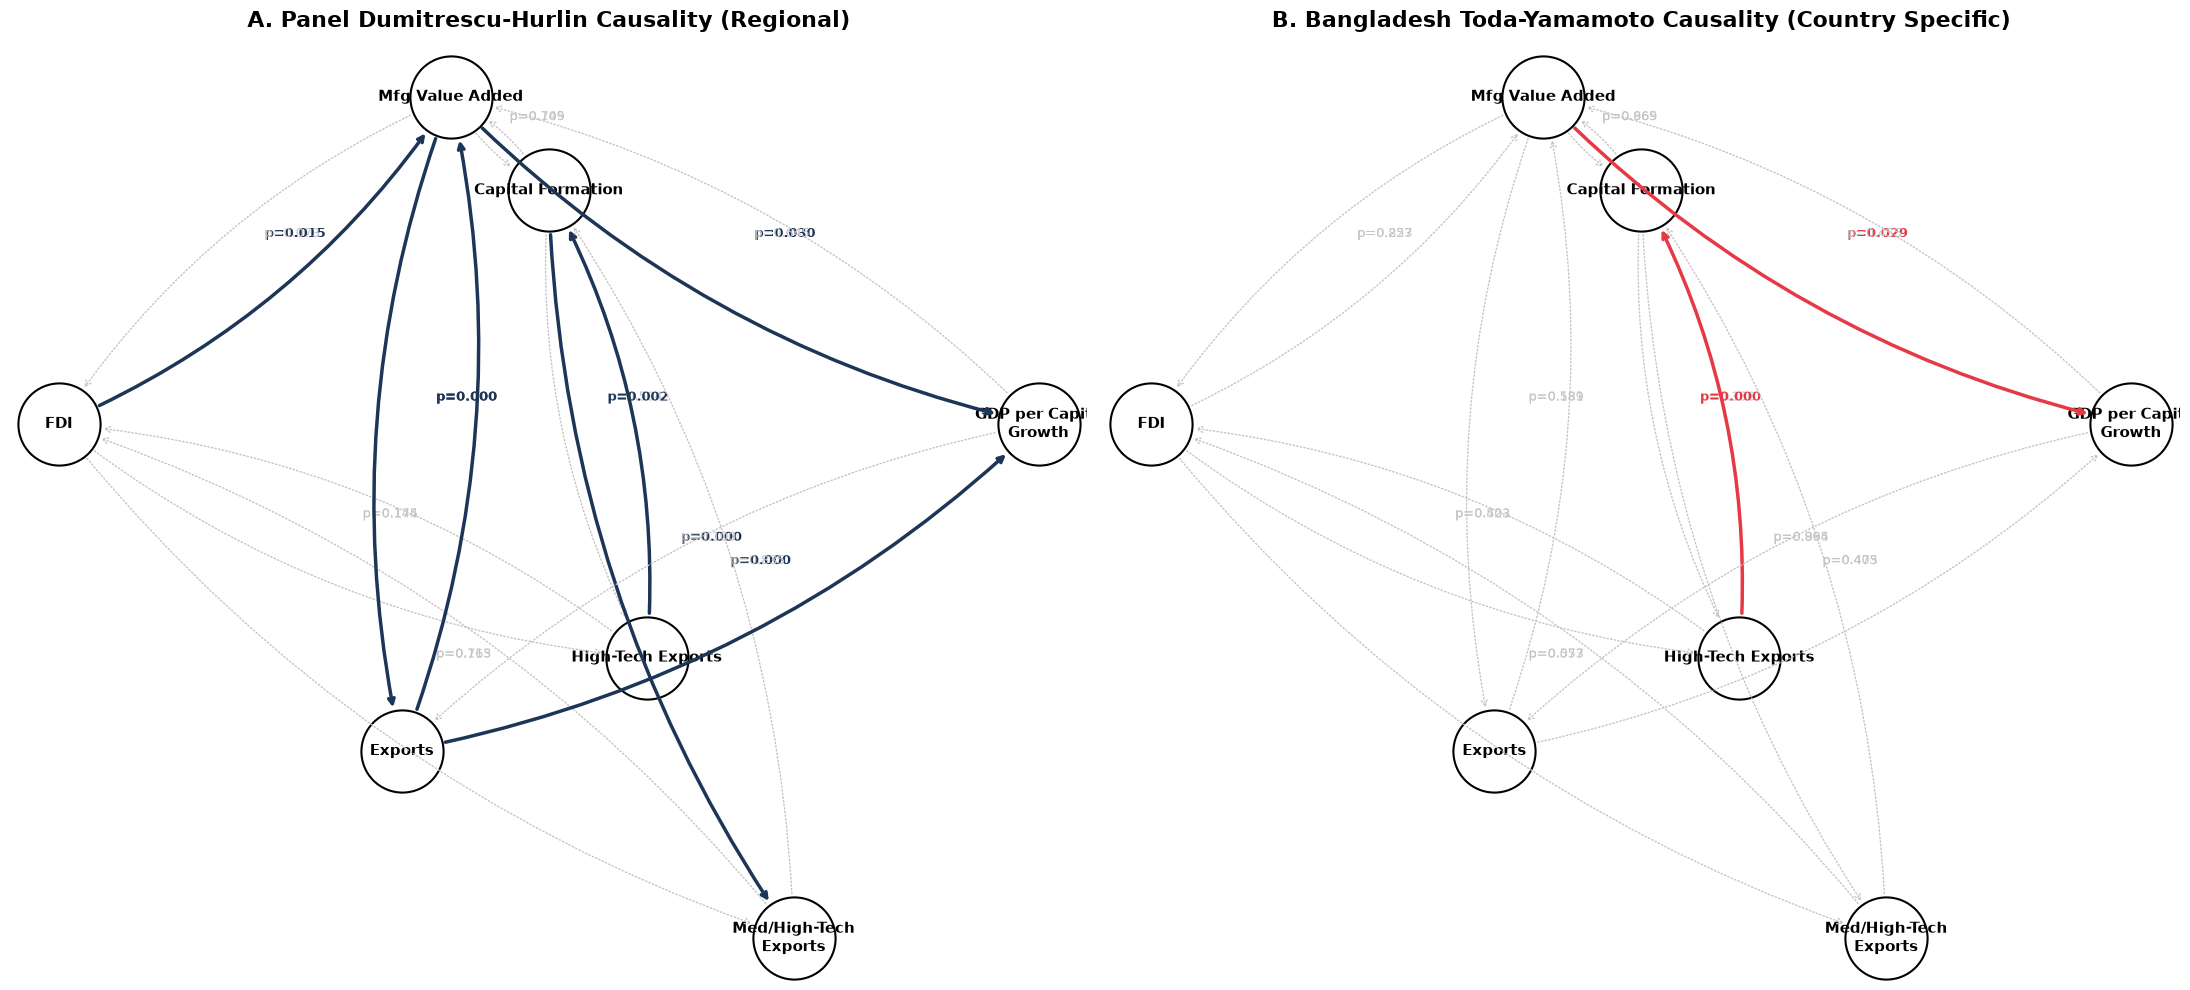

In [26]:
import networkx as nx

causal_map = {
    'Foreign direct investment, net inflows (% of GDP)': 'FDI',
    'Gross fixed capital formation (% of GDP)': 'Capital Formation',
    'Manufacturing, value added (% of GDP)': 'Mfg Value Added',
    'High-technology exports (% of manufactured exports)': 'High-Tech Exports',
    'Medium and high-tech exports (% manufactured exports)': 'Med/High-Tech\nExports',
    'Exports of goods and services (% of GDP)': 'Exports',
    'GDP per capita growth (annual %)': 'GDP per Capita\nGrowth'
}

causality_df['Source'] = causality_df['Direction'].apply(lambda d: causal_map.get(d.split(' -> ')[0]))
causality_df['Target'] = causality_df['Direction'].apply(lambda d: causal_map.get(d.split(' -> ')[1]))

pos = {
    'FDI': (0, 0.5),
    'Capital Formation': (1, 1),
    'Mfg Value Added': (0.8, 1.2),
    'High-Tech Exports': (1.2, 0),
    'Med/High-Tech\nExports': (1.5, -0.6),
    'Exports': (0.7, -0.2),
    'GDP per Capita\nGrowth': (2, 0.5)
}

fig, axes = plt.subplots(1, 2, figsize=(22, 10))

plot_configs = [
    ('A. Panel Dumitrescu-Hurlin Causality (Regional)', 'Panel DH p-val', '#1D3557', '#C4C4C4'),
    ('B. Bangladesh Toda-Yamamoto Causality (Country Specific)', 'BD TY p-val', '#E63946', '#C4C4C4')
]

for idx, (title, p_col, sig_color, base_color) in enumerate(plot_configs):
    ax = axes[idx]
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20)
    
    G = nx.DiGraph()
    G.add_nodes_from(pos.keys())
    
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color='#FFFFFF', edgecolors='#000000', node_size=3500, linewidths=1.5)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=11, font_weight='bold')
    
    for _, row in causality_df.dropna(subset=[p_col, 'Source', 'Target']).iterrows():
        p_val = row[p_col]
        u, v = row['Source'], row['Target']
        is_sig = p_val < 0.05
        
        edge_col = sig_color if is_sig else base_color
        style = 'solid' if is_sig else 'dotted'
        width = 2.5 if is_sig else 1.0
        
        ax.annotate("",
            xy=pos[v], xytext=pos[u],
            arrowprops=dict(arrowstyle="->", color=edge_col, lw=width, ls=style, shrinkA=32, shrinkB=32, patchA=None, patchB=None, connectionstyle="arc3,rad=0.15")
        )
        
        mid_x = (pos[u][0] + pos[v][0]) / 2 + 0.02
        mid_y = (pos[u][1] + pos[v][1]) / 2 + 0.05
        ax.text(mid_x, mid_y, f"p={p_val:.3f}", fontsize=9, color=edge_col, weight='bold' if is_sig else 'normal')

    ax.axis('off')

plt.tight_layout()
save_fig('fig_causality_network.png')
plt.show()

### Net trade competitiveness ratio

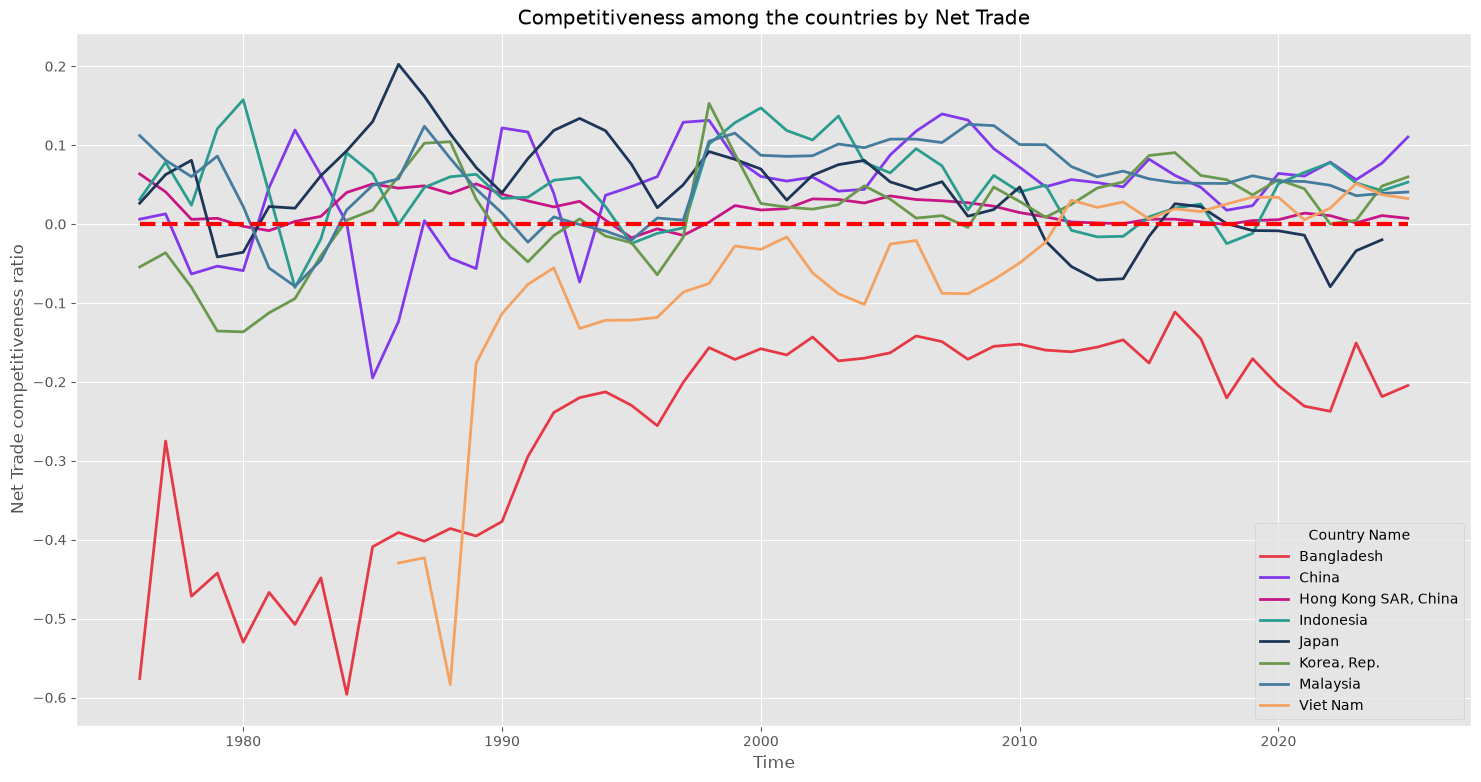

In [27]:
plt.figure(figsize = (18, 9))
sns.lineplot(data = data[data['Country Name'].isin(['Bangladesh', 'Viet Nam', 'China', 'Japan', 'Malaysia', 'Indonesia', 'Korea, Rep.', 'Hong Kong SAR, China'])], x = 'Time', y = 'Net Trade competitiveness ratio', hue = 'Country Name', palette = palette, linewidth = 2)
plt.title('Competitiveness among the countries by Net Trade')
plt.hlines(0, 1976, 2025, color = 'red', linestyles='--', linewidth = 3)
save_fig('fig_ntc.png')
plt.show()

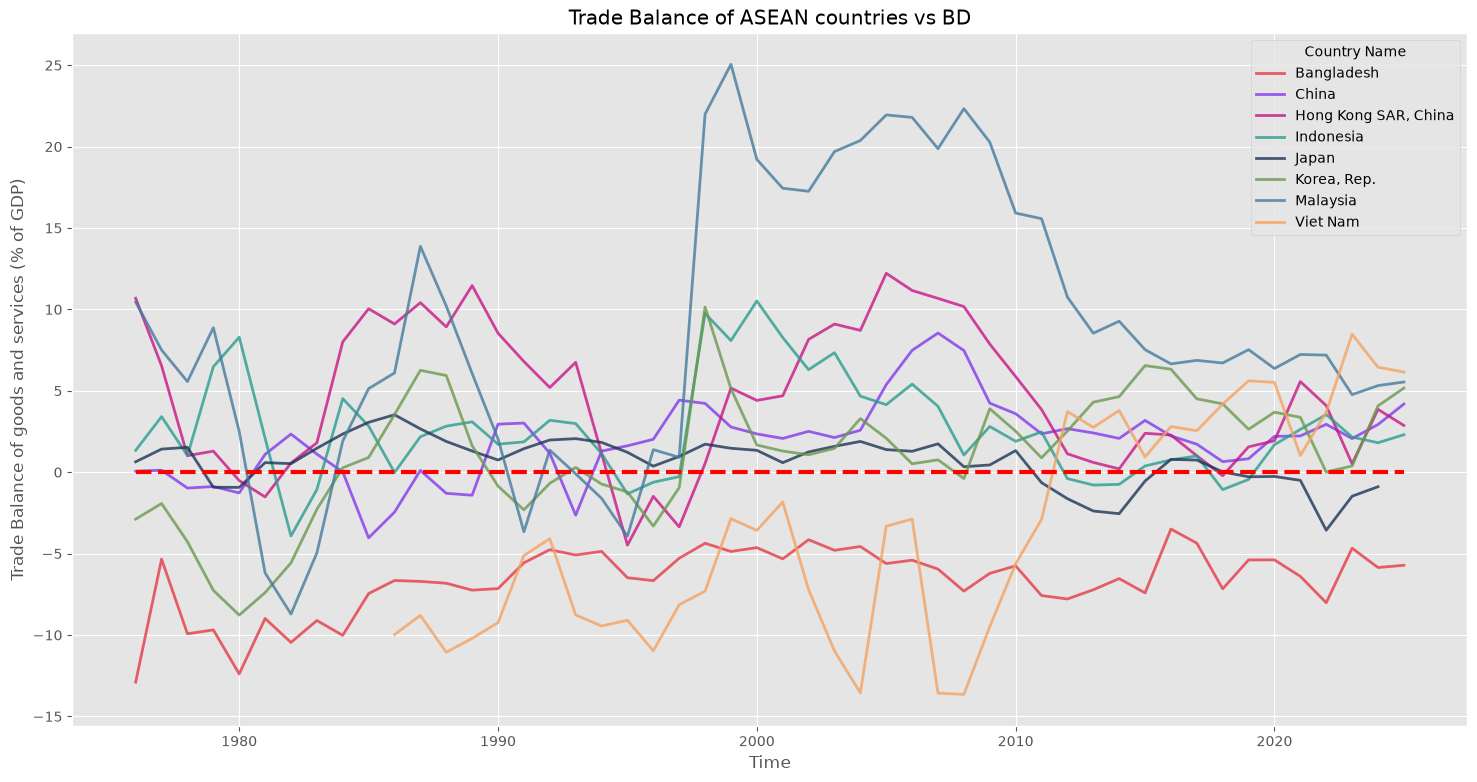

In [28]:
plt.figure(figsize = (18, 9))
sns.lineplot(data = data[data['Country Name'].isin(['Bangladesh', 'Viet Nam', 'China', 'Japan', 'Malaysia', 'Indonesia', 'Korea, Rep.', 'Hong Kong SAR, China'])], x = 'Time', y = 'Trade Balance of goods and services (% of GDP)', hue = 'Country Name', palette = palette, linewidth = 2, alpha = 0.8)
plt.title('Trade Balance of ASEAN countries vs BD')
plt.hlines(0, 1976, 2025, color = 'red', linestyles='--', linewidth = 3)
save_fig('fig_trade_balance.png')
plt.show()

## Limitations and reproducibility notes

- **Sparse series.** High-technology exports has 8-18 non-missing years per country (see the coverage table); results that use it (Kojima quadrant, high-tech causality links) are indicative only.
- **Structural breaks.** Chow results are sensitive to regime size; Zivot-Andrews break dates are informative only where the unit-root null is rejected. Compare the three Chow readings and the `Reject unit root (5%)` column before attributing a break to a specific event (for example COVID-19).
- **Levels vs. changes.** Rank correlations and Dumitrescu-Hurlin tests on trending levels can overstate dependence; the robustness cells repeat them on first differences.
- **Multiple testing.** Many break years and many causal directions are tested; Bonferroni/Holm columns are provided.
- **Figures** written to `images/`: `fig_kojima_hightech`, `fig_kojima_medhightech`, `fig_kojima_gcf`, `fig_rolling_correlation`, `fig_female_scatter`, `fig_spearman_heatmap`, `fig_zivot_andrews`, `fig_causality_network`, `fig_ntc` and `fig_trade_balance`. The paper's `fig_decomposition.png` and `fig_workflow.png` are not produced by this notebook.
- **Hong Kong SAR.** Its manufacturing, industry, services and agriculture value-added series start in 2000 (25 years), so the Chow scan, manufacturing lead-lag and any test using those variables has a short sample for Hong Kong; check `n_pre`/`n_post` before reading a break year. Its FDI inflows are an outlier among the economies compared (likely reflecting its role as an entrepot and financial centre rather than manufacturing investment), which is why the Kojima FDI axes are symmetric-log.
- **Sample window.** `wdi_data.csv` now starts in 1960, but the analysis keeps 1976-2025 (`ANALYSIS_START`) so the original nine economies are comparable with earlier results.

In [29]:
import sys, scipy, matplotlib
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | scipy {scipy.__version__} | statsmodels {statsmodels.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__} | networkx {nx.__version__}')

Python 3.15.1 | pandas 3.1.0 | numpy 2.5.4 | scipy 1.18.1 | statsmodels 0.15.0 | matplotlib 3.11.2 | seaborn 0.13.2 | networkx 3.7
